In [1]:
import numpy as np
import matplotlib.pyplot as plt
from data.molar_mass import molar_masses as mm
import pandas as pd
import seaborn as sns
import matplotlib

# read filtered data in mol per mol unitd
all_data = pd.read_csv('sample_data_mol_per_mol.csv')
all_samples = all_data['Sample Name'].unique()

# cahnge espanola sample names
change_names = lambda x: x.replace('18-2-', '')

# read data in ppm units
nitric_runs_ppb = pd.read_csv('data/nitric_acid_runs_reduced_ppb.csv')
nitric_runs_ppb['Sample Name'] = nitric_runs_ppb['Sample Name'].apply(change_names)
nitric_runs_ppb = nitric_runs_ppb[nitric_runs_ppb['Sample Name'].isin(all_samples)]

In [2]:
class dotdict(dict):
    """dot.notation access to dictionary attributes"""
    __getattr__ = dict.get
    __setattr__ = dict.__setitem__
    __delattr__ = dict.__delitem__

# Rock and diagenetic fluid compsitions
# Primary aragonite depsited in oxic column
oxic_aragonite = dotdict(dict(
    # concentrations, ppm
    C = 120000,
    Ca = 387500,
    Mn = 1, 
    Sr = 10000, 
    O = 480000, 
    Mg = 2500, 
    Ce = np.mean([0.011,0.896]),
    I = 6,
    # isotopes
    d13C = 5, # d13C
    d18O = 0, # d18O PDB
    dCe = 0.67, # Ce anomaly
))

oxic_calcite = dotdict(dict(
    # concentrations, ppm
    C = 120000,
    Ca = 394500,
    Mn = 1, 
    Sr = 500, 
    O = 480000, 
    Mg = 5000, 
    Ce = np.mean([0.011,0.896]),
    I = 6,
    # isotopes
    d13C = 3.2, # d13C
    d18O = 0, # d18O PDB
    dCe = 0.67, # Ce anomaly
))

# Primary aragonite depsited in anoxic column
anoxic_aragonite = dotdict(dict(
    # concentrations, ppm
    C = 120000,
    Ca = 387500,
    Mn = 1, 
    Sr = 10000, 
    O = 480000, 
    Mg = 2500, 
    Ce = np.mean([0.011,0.896]), # same as oxic
    I = 394500*0.1317*(7.8802e-15*mm['I'])/(0.01028*mm['I']),
    d13C = 5, # d13C
    d18O = 0, # d18O PDB
    dCe = 1.025, # Ce anomaly
))

anoxic_calcite= dotdict(dict(
    # concentrations, ppm
    C = 120000,
    Ca = 394500,
    Mn = 1, 
    Sr = 500, 
    O = 480000, 
    Mg = 5000, 
    Ce = np.mean([0.011,0.896]), # same as oxic
    I = 394500*0.1317*(7.8802e-15*mm['I'])/(0.01028*mm['I']),
    d13C = 3.2, # d13C
    d18O = 0, # d18O PDB
    dCe = 1.025, # Ce anomaly
))

# Oxic seawater
oxic_seawater = dotdict(dict( # concentrations in ppm
  C = 29, 
  Ca = 0.01028 * mm['Ca'] * 1e3,
  Mn = 2e-3,
  Sr = 8, #0.00009 * mm['Sr'] * 1e3,
  O = 889e3,
  Mg = 1295,
  Ce = 1.3132e-11 * mm['Ce'] * 1e3,
  I = 0.375e-6 * mm['I'] * 1e3,
  d13C = -15, ##1.54, # d13C VPDB
  d18O = -30.5, # d18O, VPDB -- -8 per mil SMOW
  dCe = 0.46, # Ce anomaly
  ))

# Reducing seawater
reducing_seawater = dotdict(dict( # concentrations in ppm
  C = 29,
  Ca = 0.01028 * mm['Ca'] * 1e3,
  Mn = 1,
  Sr = 10, # 0.00009 * mm['Sr'] * 1e3, 
  O = 889e3,
  Mg = 1295,
  Ce = 114e-12 * mm['Ce'] * 1e3, 
  I = 1e-9,
  d13C = -1,# np.mean((-25, 5)), # d13C VPDB
  d18O = -30.5, # d18O, VPDB
  dCe = np.mean((0.8, 1.25)), # Ce anomaly
  #dCe = 1.5, # Ce anomaly
  ))


# Meteric seawater
meteoric_fluid = dotdict(dict( # river and/or gw concentrations in ppm
  C = 10,
  Ca = 0.002*mm['Ca'] * 1e3, 
  Mn = 0.008,
  Sr = 0.06, #2.5e-6*mm['Sr'] * 1e3 * 100, 
  O = 889e3,
  Mg = np.mean((0.8, 235)),
  Ce = np.mean((10e-6, 10e-4)),
  I = 2.5091e-7 * mm['I'] * 1e3,
  d13C = -3.245,  # d13C VPDB
  d18O = -37.7434, # d18O, VPDB
  dCe = 1, #1.395, # Ce anomaly
  dI = 0.709250 
  ))

def BannerHanson(rock, fluid):
    '''
    Runs Banner Hanson diagenesis model
    Arguments:
        rock: dict with rock properties
        fluid: doct with diagenetic fluid properties
    Returns:
        rock_evolution: dict with the compositional and isotopic
        evolution of the rock and the fluid
    '''

    # Exchange reaction distribution coefficient (Kd):
    Kd_Sr = 0.025               # Kd Sr-Ca
    Kd_Mn = 0.86                     # Kd Mn-Ca
    Kd_Ce = np.mean([100,296])
    if fluid is meteoric_fluid:
        Kd_I = 0.0064
    else:
        Kd_I = 0.1317
    Kd_C = 1
    Kd_O = 1
    Kd_Ca = 1


    alpha = 1.001
    alpha_O = 1.0102 # 1.03125 # 1.0330
    alpha_Ce = 1.00

    ##
    # Single element distribution coefficient (D):
    CaCO3 = rock.Ca                  # Ca in CaCO3 (ppm)
    Ca_fl = fluid.Ca                     # Ca in fluid
    DJ = CaCO3/Ca_fl 

    D_Sr = DJ*Kd_Sr                  # for Sr
    D_Ca = DJ*Kd_Ca   
    D_Mn = DJ*Kd_Mn                  # for Mn
    D_Ce = DJ*Kd_Ce                  # for Ce
    D_I = DJ*Kd_I 
    D_C = rock.C/fluid.C*Kd_C             # for carbon
    D_O = rock.O/fluid.O*Kd_O         # for oxygen


    F = 0.5 # Weight fraction of fluid

    # Rock evoolution
    re = dotdict(dict(
        Ca = np.zeros(int(1e6)),
        Sr = np.zeros(int(1e6)),
        Mn = np.zeros(int(1e6)),
        Ce = np.zeros(int(1e6)),
        I = np.zeros(int(1e6)),
        C = np.zeros(int(1e6)),
        O = np.zeros(int(1e6)),
        d13C = np.zeros(int(1e6)),
        d18O = np.zeros(int(1e6)),
        dCe = np.zeros(int(1e6)),
        N = np.zeros(int(1e6))
    ))

    # initial concentrations
    re['Sr'][0] = rock['Sr']
    re['Ca'][0] = rock['Ca']
    re['Mn'][0] = rock['Mn']
    re['Ce'][0] = rock['Ce']
    re['I'][0] = rock['I']
    re['C'][0] = rock['C']
    re['O'][0] = rock['O']
    re['N'][0] = 1

    # rock-fluid system
    rs = dotdict(dict(
        Sr = np.zeros(int(1e6)),
        Ca = np.zeros(int(1e6)),
        Mn = np.zeros(int(1e6)),
        Ce = np.zeros(int(1e6)),
        I = np.zeros(int(1e6)),
        C = np.zeros(int(1e6)),
        O = np.zeros(int(1e6)),
        d13C = np.zeros(int(1e6)),
        d18O = np.zeros(int(1e6)),
        dCe = np.zeros(int(1e6)),
        N = np.zeros(int(1e6))
    ))

    # fluid
    Cf_Sr = np.zeros(2)
    Cf_Sr[0] = fluid['Sr']
    Cf_Ca = np.zeros(2)
    Cf_Ca[0] = fluid['Ca']
    Cf_Mn = np.zeros(2)
    Cf_Mn[0] = fluid['Mn']
    Cf_Ce = np.zeros(2)
    Cf_Ce[0] = fluid['Ce']
    Cf_I = np.zeros(2)
    Cf_I[0] = fluid['I']
    Cf_C = np.zeros(2)
    Cf_C[0] = fluid['C']
    Cf_O = np.zeros(2)
    Cf_O[0] = fluid['O']
    d13C_f = fluid['d13C']
    d18O_f = fluid['d18O']
    dCe_f = fluid['dCe']


    rs.Sr[0] = F*Cf_Sr[0] + (1 - F)*re.Sr[0] 
    rs.Ca[0] = F*Cf_Ca[0] + (1 - F)*re.Ca[0] 
    rs.Mn[0] = F*Cf_Mn[0] + (1 - F)*re.Mn[0] 
    rs.Ce[0] = F*Cf_Ce[0] + (1 - F)*re.Ce[0] 
    rs.I[0] = F*Cf_I[0] + (1 - F)*re.I[0] 
    rs.C[0] = F*Cf_C[0] + (1 - F)*re.C[0] 
    rs.O[0] = F*Cf_O[0] + (1 - F)*re.O[0]

    # Initial isotopes of the system:
    re.d13C[0] = rock['d13C']
    re.d18O[0] = rock['d18O']
    re.dCe[0] = rock['dCe']

    rs.d13C[0] = (d13C_f*Cf_C[0]*F + re.d13C[0]*re.C[0]*(1 - F))/rs.C[0] 
    rs.d18O[0] = (d18O_f*Cf_O[0]*F + re.d18O[0]*re.O[0]*(1 - F))/rs.O[0] 
    rs.dCe[0]  = (dCe_f*Cf_Ce[0]*F + re.dCe[0]*re.Ce[0]*(1 - F))/rs.Ce[0] 

    ##
    # Closed-system equilibration:

    # Partitioning Sr into the rock:
    re.Sr[1] = rs.Sr[0]/(F/D_Sr + (1 - F)) 
    re.Ca[1] = rs.Ca[0]/(F/D_Ca + (1 - F)) 
    re.Mn[1] = rs.Mn[0]/(F/D_Mn + (1 - F)) 
    re.Ce[1] = rs.Ce[0]/(F/D_Ce + (1 - F)) 
    re.I[1] = rs.I[0]/(F/D_I + (1 - F)) 
    re.C[1] = rs.C[0]/(F/D_C + (1 - F)) 
    re.O[1] = rs.O[0]/(F/D_O + (1 - F)) 

    # Partitioning into the fluid:
    Cf_Sr[1] = re.Sr[1]/D_Sr 
    Cf_Ca[1] = re.Ca[1]/D_Ca 
    Cf_Mn[1] = re.Mn[1]/D_Mn
    Cf_Ce[1] = re.Ce[1]/D_Ce 
    Cf_I[1] = re.I[1]/D_I 
    Cf_C[1] = re.C[1]/D_C 
    Cf_O[1] = re.O[1]/D_O 

    # Check for mass balance:
    rs.Sr[1] = F*Cf_Sr[1] + (1 - F)*re.Sr[1] 
    rs.Ca[1] = F*Cf_Ca[1] + (1 - F)*re.Ca[1] 
    rs.Mn[1] = F*Cf_Mn[1] + (1 - F)*re.Mn[1] 
    rs.Ce[1] = F*Cf_Ce[1] + (1 - F)*re.Ce[1] 
    rs.I[1] = F*Cf_I[1] + (1 - F)*re.I[1] 
    rs.C[1] = F*Cf_C[1] + (1 - F)*re.C[1] 
    rs.O[1] = F*Cf_O[1] + (1 - F)*re.O[1] 

    # step 2 isotopes of the system:
    re.d13C[1] = (rs.d13C[0]*rs.C[1] - F*d13C_f*Cf_C[1])/((1 - F)*re.C[1]) 
    rs.d13C[1] = (d13C_f*Cf_C[1]*F + re.d13C[1]*re.C[1]*(1 - F))/rs.C[1] 

    re.d18O[1] = (rs.d18O[0]*rs.O[1] - F*d18O_f*Cf_O[1])/((1 - F)*re.O[1]) 
    rs.d18O[1] = (d18O_f*Cf_O[1]*F + re.d18O[1]*re.O[1]*(1 - F))/rs.O[1] 

    re.dCe[1] = (rs.dCe[0]*rs.Ce[1] - F*dCe_f*Cf_Ce[1])/((1 - F)*re.Ce[1]) 
    rs.dCe[1] = (dCe_f*Cf_Ce[1]*F + re.dCe[1]*re.Ce[1]*(1 - F))/rs.Ce[1] 


    ##

    # Open-system equilibration (Cf_I does not change!):
    for i in range(1, int(1e6)):

        # partitioning into the rock:
        re.Sr[i] = rs.Sr[i-1]/(F/D_Sr + (1 - F)) 
        re.Ca[i] = rs.Ca[i-1]/(F/D_Ca + (1 - F)) 
        re.Mn[i] = rs.Mn[i-1]/(F/D_Mn + (1 - F))
        re.Ce[i] = rs.Ce[i-1]/(F/D_Ce + (1 - F)) 
        re.I[i] = rs.I[i-1]/(F/D_I + (1 - F)) 
        re.C[i] = rs.C[i-1]/(F/D_C + (1 - F)) 
        re.O[i] = rs.O[i-1]/(F/D_O + (1 - F)) 

        # calculate new mass of system:
        rs.Sr[i] = F*Cf_Sr[0] + (1 - F)*re.Sr[i] 
        rs.Ca[i] = F*Cf_Ca[0] + (1 - F)*re.Ca[i] 
        rs.Mn[i] = F*Cf_Mn[0] + (1 - F)*re.Mn[i]
        rs.Ce[i] = F*Cf_Ce[0] + (1 - F)*re.Ce[i] 
        rs.I[i] = F*Cf_I[0] + (1 - F)*re.I[i] 
        rs.C[i] = F*Cf_C[0] + (1 - F)*re.C[i] 
        rs.O[i] = F*Cf_O[0] + (1 - F)*re.O[i] 

        # isotopes:
        #rs.d13C[i] = rs.d13C[i-1]                       # no fractionations
        #rs.d18O[i] = rs.d18O[i-1] 

        # with fractionation
        re.d13C[i] = (rs.d13C[i-1]*rs.C[i]*alpha - F*Cf_C[0]*1000*(1-alpha))/\
            (F*Cf_C[0] + alpha*(1-F)*re.C[i]) 

        rs.d13C[i] = (d13C_f*Cf_C[0]*F + re.d13C[i]*re.C[i]*(1 - F))/rs.C[i] 


        re.d18O[i] = (rs.d18O[i-1]*rs.O[i]*alpha_O - F*Cf_O[0]*1000*(1-alpha_O))/\
            (F*Cf_O[0] + alpha_O*(1-F)*re.O[i]) 

        rs.d18O[i] = (d18O_f*Cf_O[0]*F + re.d18O[i]*re.O[i]*(1 - F))/rs.O[i]

        re.dCe[i] = (rs.dCe[i-1]*rs.Ce[i]*alpha_Ce - F*Cf_Ce[0]*1000*(1-alpha_Ce))/\
            (F*Cf_Ce[0] + alpha_Ce*(1-F)*re.Ce[i]) 
    
        rs.dCe[i] = (dCe_f*Cf_Ce[0]*F + re.dCe[i]*re.Ce[i]*(1 - F))/rs.Ce[i] 

        # cummulative fluid:rock ratio
        re.N[i] = i*F/(1-F) 
        rs.N[i] = i*F/(1-F)
        
    return re, rs


In [3]:
re_mtfl_ox, rs_mtfl_ox = BannerHanson(rock=oxic_aragonite, fluid=meteoric_fluid)
re_oxsw_ox, rs_oxsw_ox = BannerHanson(rock=oxic_aragonite, fluid=oxic_seawater)
re_rdsw_ox, rs_rdsw_ox = BannerHanson(rock=oxic_aragonite, fluid=reducing_seawater)

re_mtfl_ax, rs_mtfl_ax = BannerHanson(rock=anoxic_aragonite, fluid=meteoric_fluid)
re_oxsw_ax, rs_oxsw_ax = BannerHanson(rock=anoxic_aragonite, fluid=oxic_seawater)
re_rdsw_ax, rs_rdsw_ax = BannerHanson(rock=anoxic_aragonite, fluid=reducing_seawater)

/var/folders/5v/vrzl4plx1598hr5q_5ssvl3r0000gn/T/ipykernel_91326/3190411885.py:270: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend(fontsize=7, frameon=False)
/var/folders/5v/vrzl4plx1598hr5q_5ssvl3r0000gn/T/ipykernel_91326/3190411885.py:370: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.savefig('plots/BannerHanson_model.pdf', bbox_inches='tight')
/var/folders/5v/vrzl4plx1598hr5q_5ssvl3r0000gn/T/ipykernel_91326/3190411885.py:370: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.savefig('plots/BannerHanson_model.pdf', bbox_inches='tight')
/opt/anaconda3/envs/chempath/lib/python3.10/site-packages/IPython/core/pylabtools.py:170: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


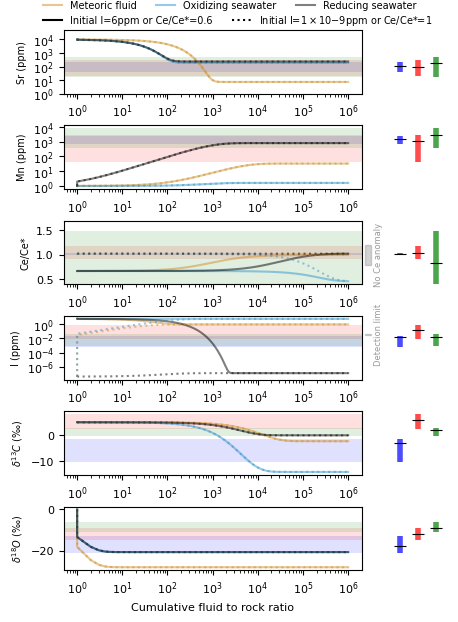

In [4]:
# plot mode results
a4_x, a4_y = (8.27, 11.69)

import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from matplotlib.ticker import LogLocator, NullFormatter
from matplotlib.lines import Line2D


matplotlib.rc('xtick', labelsize=8)
matplotlib.rc('ytick', labelsize=8)

# ==========================================================
# Shared extent definitions (USED EVERYWHERE)
# ==========================================================
extent_ranges = [(90, 0.5e5), (60, 1e6), (100, 1e6)]
extent_colors = ['green', 'red', 'blue']

# ==========================================================
# Helper functions
# ==========================================================
def formation_extent_bars_with_mean(
    ax, data, ycol, groupcol='formation',
    colors=('b','r','g'), width_frac=0.2,
    factor=1e3
):
    groups = sorted(data[groupcol].unique())
    x_positions = np.linspace(0.2, 0.8, len(groups))
    
    for formation, color, xpos in zip(groups, colors, x_positions):
        vals = data[data[groupcol] == formation][ycol].dropna()
        if ax.get_yscale() == 'log':
            vals = vals[vals > 0]
        if len(vals) == 0:
            continue
        
        y_min, y_max = vals.min()/factor, vals.max()/factor
        y_mean = vals.mean()/factor
        
        ax.vlines(x=xpos, ymin=y_min, ymax=y_max, color=color, lw=4, alpha=0.7)
        ax.hlines(y=y_mean, xmin=xpos-width_frac/2, xmax=xpos+width_frac/2,
                  color='k', lw=0.8)
    
    ax.set_xlim(0, 1)
    ax.axis('off')

def formation_horizontal_extent_shading(
    ax, data, ycol, groupcol='formation',
    colors=('b','r','g'), alpha=0.12, zorder=0, factor=1e3
):
    groups = sorted(data[groupcol].unique())
    for formation, color in zip(groups, colors):
        vals = data[data[groupcol] == formation][ycol].dropna()
        if ax.get_yscale() == 'log':
            vals = vals[vals > 0]
        if len(vals) == 0:
            continue
        ax.axhspan(vals.min()/factor, vals.max()/factor,
                   facecolor=color, alpha=alpha, zorder=zorder)

def extent_bars_above_axis(
    ax, x_ranges, y_top=1.5, height=0.02, dy=0.06,
    colors=None, alpha=0.4
):
    if colors is None:
        colors = ['k'] * len(x_ranges)

    xlim = ax.get_xlim()

    for i, ((x1, x2), color) in enumerate(zip(x_ranges, colors)):
        y = y_top - i * dy

        xa = (np.log10(x1) - np.log10(xlim[0])) / (np.log10(xlim[1]) - np.log10(xlim[0]))
        xb = (np.log10(x2) - np.log10(xlim[0])) / (np.log10(xlim[1]) - np.log10(xlim[0]))

        ax.add_patch(
            plt.Rectangle(
                (xa, y), xb - xa, height,
                transform=ax.transAxes,
                facecolor=color,
                edgecolor=color,
                alpha=alpha,
                clip_on=False
            )
        )

def vertical_y_range_bar_outside(
    ax, y1, y2,
    label=None,
    x_left=1.01, width=0.02,
    color='gray', alpha=0.35,
    label_offset=0.01, label_size=6
):
    """
    Vertical bar outside axis spanning y1–y2 (data coords),
    with optional vertical label.
    """
    ylim = ax.get_ylim()

    if ax.get_yscale() == 'log':
        ya = (np.log10(y1) - np.log10(ylim[0])) / (np.log10(ylim[1]) - np.log10(ylim[0]))
        yb = (np.log10(y2) - np.log10(ylim[0])) / (np.log10(ylim[1]) - np.log10(ylim[0]))
    else:
        ya = (y1 - ylim[0]) / (ylim[1] - ylim[0])
        yb = (y2 - ylim[0]) / (ylim[1] - ylim[0])

    # bar
    ax.add_patch(
        plt.Rectangle(
            (x_left, ya),
            width,
            yb - ya,
            transform=ax.transAxes,
            facecolor=color,
            edgecolor=color,
            alpha=alpha,
            clip_on=False
        )
    )

    # label
    if label is not None:
        ax.text(
            x_left + width + label_offset,
            0.5 * (ya + yb),
            label,
            transform=ax.transAxes,
            rotation=90,
            va='center',
            ha='left',
            fontsize=label_size,
            color=color,
            alpha=0.8,
            clip_on=False
        )

# ==========================================================
# Figure
# ==========================================================
fig, axs = plt.subplots(
    6, 2,
    figsize=[a4_x * 0.6, a4_y * 0.6],
    gridspec_kw={'width_ratios': [5, 1]},
    sharey='row'
)

# -------------------------
# Sr
# -------------------------
ax = axs[0][0]
ax.plot(re_mtfl_ox.N, re_mtfl_ax.Sr, color='#CF8F27', alpha=0.5, label='Meteoric fluid')
ax.plot(re_oxsw_ox.N, re_oxsw_ax.Sr, color='#3396CC', alpha=0.5, label='Oxidizing seawater')
ax.plot(re_rdsw_ox.N, re_rdsw_ax.Sr, color='k', alpha=0.5, label='Reducing seawater')
ax.plot(re_mtfl_ax.N, re_mtfl_ax.Sr, ls=':', color='#CF8F27', alpha=0.5)
ax.plot(re_oxsw_ax.N, re_oxsw_ax.Sr, ls=':', color='#3396CC', alpha=0.5)
ax.plot(re_rdsw_ax.N, re_rdsw_ax.Sr, ls=':', color='k', alpha=0.5)

ax.set_ylabel('Sr (ppm)', fontsize=7)
ax.set_xscale('log')
ax.set_yscale('log')
ax.set_ylim(1, 5e4)
ax.yaxis.set_major_locator(LogLocator(base=10, numticks=8))


# ax.legend(fontsize=7, frameon=False, ncol=3,
#           loc='upper left', bbox_to_anchor=(-0.1, 1.4))

# ----------------------------------------------------------
# Legend 1: fluid types
# ----------------------------------------------------------
fluid_handles, fluid_labels = ax.get_legend_handles_labels()

legend1 = ax.legend(
    handles=fluid_handles,
    labels=fluid_labels,
    fontsize=7,
    frameon=False,
    ncol=3,
    loc='upper left',
    bbox_to_anchor=(-0.1, 1.6)
)

# Keep the first legend
ax.add_artist(legend1)


# ----------------------------------------------------------
# Legend 2: sample line styles
# ----------------------------------------------------------
sample_handles = [
    Line2D(
        [0], [0],
        color='k',
        lw=1.5,
        ls='-',
        label='Initial I=6ppm or Ce/Ce*=0.6'
    ),
    Line2D(
        [0], [0],
        color='k',
        lw=1.5,
        ls=':',
        label=r'Initial I=$1\times10{-9}$ppm or Ce/Ce*=1'
    )
]

ax.legend(
    handles=sample_handles,
    fontsize=7,
    frameon=False,
    ncol=2,
    loc='upper left',
    bbox_to_anchor=(-0.1, 1.4)
)



formation_horizontal_extent_shading(
    ax, nitric_runs_ppb, '88  Sr  [ No Gas ]'
)

formation_extent_bars_with_mean(
    axs[0][1], nitric_runs_ppb, '88  Sr  [ No Gas ]'
)

# -------------------------
# Mn
# -------------------------
ax = axs[1][0]
ax.plot(re_mtfl_ox.N, re_mtfl_ox.Mn, color='#CF8F27', alpha=0.5)
ax.plot(re_oxsw_ox.N, re_oxsw_ox.Mn, color='#3396CC', alpha=0.5)
ax.plot(re_rdsw_ox.N, re_rdsw_ox.Mn, color='k', alpha=0.5)
ax.plot(re_mtfl_ax.N, re_mtfl_ax.Mn, ls=':', color='#CF8F27', alpha=0.5)
ax.plot(re_oxsw_ax.N, re_oxsw_ax.Mn, ls=':', color='#3396CC', alpha=0.5)
ax.plot(re_rdsw_ax.N, re_rdsw_ax.Mn, ls=':', color='k', alpha=0.5)

ax.set_ylabel('Mn (ppm)', fontsize=7)
ax.set_xscale('log')
ax.set_yscale('log')
ax.yaxis.set_major_locator(LogLocator(base=10, numticks=5))



formation_horizontal_extent_shading(
    ax, nitric_runs_ppb, '55 -> 55  Mn  [ H2 ]'
)

formation_extent_bars_with_mean(
    axs[1][1], nitric_runs_ppb, '55 -> 55  Mn  [ H2 ]'
)

# -------------------------
# Ce anomaly
# -------------------------
ax = axs[2][0]
ax.plot(re_mtfl_ox.N, re_mtfl_ox.dCe, color='#CF8F27', alpha=0.5)
ax.plot(re_oxsw_ox.N, re_oxsw_ox.dCe, color='#3396CC', alpha=0.5)
ax.plot(re_rdsw_ox.N, re_rdsw_ox.dCe, color='k', alpha=0.5)
ax.plot(re_mtfl_ax.N, re_mtfl_ax.dCe, ls=':', color='#CF8F27', alpha=0.5)
ax.plot(re_oxsw_ax.N, re_oxsw_ax.dCe, ls=':', color='#3396CC', alpha=0.5)
ax.plot(re_rdsw_ax.N, re_rdsw_ax.dCe, ls=':', color='k', alpha=0.5)

ax.set_ylabel(r'Ce/Ce*', fontsize=7)
ax.set_xscale('log')
ax.set_ylim(0.4, 1.7)

# legend retained (semantic)
ax.legend(fontsize=7, frameon=False)

vertical_y_range_bar_outside(ax, 0.8, 1.2, label='No Ce anomaly')

formation_horizontal_extent_shading(
    ax, all_data, 'Ce_anomaly_geom', factor=1
)

formation_extent_bars_with_mean(
    axs[2][1], all_data, 'Ce_anomaly_geom', factor=1
)

# -------------------------
# I
# -------------------------
ax = axs[3][0]
ax.plot(re_mtfl_ox.N, re_mtfl_ox.I, color='#CF8F27', alpha=0.5)
ax.plot(re_oxsw_ox.N, re_oxsw_ox.I, color='#3396CC', alpha=0.5)
ax.plot(re_rdsw_ox.N, re_rdsw_ox.I, color='k', alpha=0.5)
ax.plot(re_mtfl_ax.N, re_mtfl_ax.I, ls=':', color='#CF8F27', alpha=0.5)
ax.plot(re_oxsw_ax.N, re_oxsw_ax.I, ls=':', color='#3396CC', alpha=0.5)
ax.plot(re_rdsw_ax.N, re_rdsw_ax.I, ls=':', color='k', alpha=0.5)

ax.set_ylabel('I (ppm)', fontsize=7)
ax.set_xscale('log')
ax.set_yscale('log')
ax.yaxis.set_major_locator(LogLocator(base=10, numticks=7))

I_detection_min = 30 /1e3
I_detection_max = 50 /1e3

vertical_y_range_bar_outside(
    ax, I_detection_min, I_detection_max, label='Detection limit'
)

formation_horizontal_extent_shading(
    ax, nitric_runs_ppb, '127  I  [ No Gas ]'
)

# axs[3][1].set_yscale('log')
formation_extent_bars_with_mean(
    axs[3][1], nitric_runs_ppb, '127  I  [ No Gas ]'
)
ax.set_xlabel('Fluid to rock ratio (N)', fontsize=8)

# -------------------------
# d13C
# -------------------------
ax = axs[4][0]
ax.plot(re_mtfl_ox.N, re_mtfl_ox.d13C, color='#CF8F27', alpha=0.5)
ax.plot(re_oxsw_ox.N, re_oxsw_ox.d13C, color='#3396CC', alpha=0.5)
ax.plot(re_rdsw_ox.N, re_rdsw_ox.d13C, color='k', alpha=0.5)
ax.plot(re_mtfl_ax.N, re_mtfl_ax.d13C, ls=':', color='#CF8F27', alpha=0.5)
ax.plot(re_oxsw_ax.N, re_oxsw_ax.d13C, ls=':', color='#3396CC', alpha=0.5)
ax.plot(re_rdsw_ax.N, re_rdsw_ax.d13C, ls=':', color='k', alpha=0.5)

ax.set_ylabel(r'$\delta^{13}C$ (‰)', fontsize=7)
ax.set_xscale('log')

formation_horizontal_extent_shading(
    ax, all_data, 'd13c_sp', factor=1
)

formation_extent_bars_with_mean(
    axs[4][1], all_data, 'd13c_sp', factor=1
)

# -------------------------
# d18O
# -------------------------
ax = axs[5][0]
ax.plot(re_mtfl_ox.N, re_mtfl_ox.d18O, color='#CF8F27', alpha=0.5)
ax.plot(re_oxsw_ox.N, re_oxsw_ox.d18O, color='#3396CC', alpha=0.5)
ax.plot(re_rdsw_ox.N, re_rdsw_ox.d18O, color='k', alpha=0.5)
ax.plot(re_mtfl_ax.N, re_mtfl_ax.d18O, ls=':', color='#CF8F27', alpha=0.5)
ax.plot(re_oxsw_ax.N, re_oxsw_ax.d18O, ls=':', color='#3396CC', alpha=0.5)
ax.plot(re_rdsw_ax.N, re_rdsw_ax.d18O, ls=':', color='k', alpha=0.5)

ax.set_ylabel(r'$\delta^{18}O$ (‰)', fontsize=7)
ax.set_xlabel('Cumulative fluid to rock ratio', fontsize=8)
ax.set_xscale('log')

formation_horizontal_extent_shading(
    ax, all_data, 'd18o_sp', factor=1
)

formation_extent_bars_with_mean(
    axs[5][1], all_data, 'd18o_sp', factor=1
)
axs[5][1].set_xlabel('Extent', fontsize=8)

# ==========================================================
# Sync y-axis for both columns
# ==========================================================
fig.canvas.draw()
for i in range(4):
    ymin, ymax = axs[i][0].get_ylim()
    axs[i][1].set_ylim(ymin, ymax)

plt.subplots_adjust(wspace=0.15, hspace=0.5)
plt.savefig('plots/BannerHanson_model.pdf', bbox_inches='tight')
# plt.close()

In [5]:
re_calc_mtfl_ox, rs_calc_mtfl_ox = BannerHanson(rock=oxic_calcite, fluid=meteoric_fluid)
re_calc_oxsw_ox, rs_calc_oxsw_ox = BannerHanson(rock=oxic_calcite, fluid=oxic_seawater)
re_calc_rdsw_ox, rs_calc_rdsw_ox = BannerHanson(rock=oxic_calcite, fluid=reducing_seawater)

re_calc_mtfl_ax, rs_calc_mtfl_ax = BannerHanson(rock=anoxic_calcite, fluid=meteoric_fluid)
re_calc_oxsw_ax, rs_calc_oxsw_ax = BannerHanson(rock=anoxic_calcite, fluid=oxic_seawater)
re_calc_rdsw_ax, rs_calc_rdsw_ax = BannerHanson(rock=anoxic_calcite, fluid=reducing_seawater)

/var/folders/5v/vrzl4plx1598hr5q_5ssvl3r0000gn/T/ipykernel_91326/3803997683.py:270: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend(fontsize=7, frameon=False)
/var/folders/5v/vrzl4plx1598hr5q_5ssvl3r0000gn/T/ipykernel_91326/3803997683.py:370: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.savefig('plots/BannerHanson_model_calcite.pdf', bbox_inches='tight')
/var/folders/5v/vrzl4plx1598hr5q_5ssvl3r0000gn/T/ipykernel_91326/3803997683.py:370: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.savefig('plots/BannerHanson_model_calcite.pdf', bbox_inches='tight')
/opt/anaconda3/envs/chempath/lib/python3.10/site-packages/IPython/core/pylabtools.py:170: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


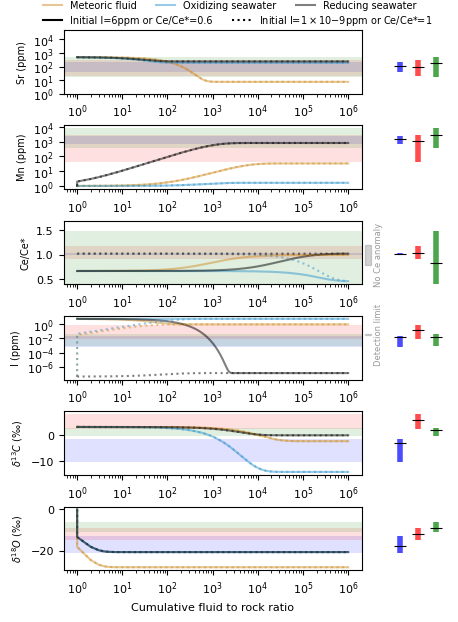

In [6]:
# plot mode results
a4_x, a4_y = (8.27, 11.69)

import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from matplotlib.ticker import LogLocator, NullFormatter
from matplotlib.lines import Line2D


matplotlib.rc('xtick', labelsize=8)
matplotlib.rc('ytick', labelsize=8)

# ==========================================================
# Shared extent definitions (USED EVERYWHERE)
# ==========================================================
extent_ranges = [(90, 0.5e5), (60, 1e6), (100, 1e6)]
extent_colors = ['green', 'red', 'blue']

# ==========================================================
# Helper functions
# ==========================================================
def formation_extent_bars_with_mean(
    ax, data, ycol, groupcol='formation',
    colors=('b','r','g'), width_frac=0.2,
    factor=1e3
):
    groups = sorted(data[groupcol].unique())
    x_positions = np.linspace(0.2, 0.8, len(groups))
    
    for formation, color, xpos in zip(groups, colors, x_positions):
        vals = data[data[groupcol] == formation][ycol].dropna()
        if ax.get_yscale() == 'log':
            vals = vals[vals > 0]
        if len(vals) == 0:
            continue
        
        y_min, y_max = vals.min()/factor, vals.max()/factor
        y_mean = vals.mean()/factor
        
        ax.vlines(x=xpos, ymin=y_min, ymax=y_max, color=color, lw=4, alpha=0.7)
        ax.hlines(y=y_mean, xmin=xpos-width_frac/2, xmax=xpos+width_frac/2,
                  color='k', lw=0.8)
    
    ax.set_xlim(0, 1)
    ax.axis('off')

def formation_horizontal_extent_shading(
    ax, data, ycol, groupcol='formation',
    colors=('b','r','g'), alpha=0.12, zorder=0, factor=1e3
):
    groups = sorted(data[groupcol].unique())
    for formation, color in zip(groups, colors):
        vals = data[data[groupcol] == formation][ycol].dropna()
        if ax.get_yscale() == 'log':
            vals = vals[vals > 0]
        if len(vals) == 0:
            continue
        ax.axhspan(vals.min()/factor, vals.max()/factor,
                   facecolor=color, alpha=alpha, zorder=zorder)

def extent_bars_above_axis(
    ax, x_ranges, y_top=1.5, height=0.02, dy=0.06,
    colors=None, alpha=0.4
):
    if colors is None:
        colors = ['k'] * len(x_ranges)

    xlim = ax.get_xlim()

    for i, ((x1, x2), color) in enumerate(zip(x_ranges, colors)):
        y = y_top - i * dy

        xa = (np.log10(x1) - np.log10(xlim[0])) / (np.log10(xlim[1]) - np.log10(xlim[0]))
        xb = (np.log10(x2) - np.log10(xlim[0])) / (np.log10(xlim[1]) - np.log10(xlim[0]))

        ax.add_patch(
            plt.Rectangle(
                (xa, y), xb - xa, height,
                transform=ax.transAxes,
                facecolor=color,
                edgecolor=color,
                alpha=alpha,
                clip_on=False
            )
        )

def vertical_y_range_bar_outside(
    ax, y1, y2,
    label=None,
    x_left=1.01, width=0.02,
    color='gray', alpha=0.35,
    label_offset=0.01, label_size=6
):
    """
    Vertical bar outside axis spanning y1–y2 (data coords),
    with optional vertical label.
    """
    ylim = ax.get_ylim()

    if ax.get_yscale() == 'log':
        ya = (np.log10(y1) - np.log10(ylim[0])) / (np.log10(ylim[1]) - np.log10(ylim[0]))
        yb = (np.log10(y2) - np.log10(ylim[0])) / (np.log10(ylim[1]) - np.log10(ylim[0]))
    else:
        ya = (y1 - ylim[0]) / (ylim[1] - ylim[0])
        yb = (y2 - ylim[0]) / (ylim[1] - ylim[0])

    # bar
    ax.add_patch(
        plt.Rectangle(
            (x_left, ya),
            width,
            yb - ya,
            transform=ax.transAxes,
            facecolor=color,
            edgecolor=color,
            alpha=alpha,
            clip_on=False
        )
    )

    # label
    if label is not None:
        ax.text(
            x_left + width + label_offset,
            0.5 * (ya + yb),
            label,
            transform=ax.transAxes,
            rotation=90,
            va='center',
            ha='left',
            fontsize=label_size,
            color=color,
            alpha=0.8,
            clip_on=False
        )

# ==========================================================
# Figure
# ==========================================================
fig, axs = plt.subplots(
    6, 2,
    figsize=[a4_x * 0.6, a4_y * 0.6],
    gridspec_kw={'width_ratios': [5, 1]},
    sharey='row'
)

# -------------------------
# Sr
# -------------------------
ax = axs[0][0]
ax.plot(re_calc_mtfl_ox.N, re_calc_mtfl_ax.Sr, color='#CF8F27', alpha=0.5, label='Meteoric fluid')
ax.plot(re_calc_oxsw_ox.N, re_calc_oxsw_ax.Sr, color='#3396CC', alpha=0.5, label='Oxidizing seawater')
ax.plot(re_calc_rdsw_ox.N, re_calc_rdsw_ax.Sr, color='k', alpha=0.5, label='Reducing seawater')
ax.plot(re_calc_mtfl_ax.N, re_calc_mtfl_ax.Sr, ls=':', color='#CF8F27', alpha=0.5)
ax.plot(re_calc_oxsw_ax.N, re_calc_oxsw_ax.Sr, ls=':', color='#3396CC', alpha=0.5)
ax.plot(re_calc_rdsw_ax.N, re_calc_rdsw_ax.Sr, ls=':', color='k', alpha=0.5)

ax.set_ylabel('Sr (ppm)', fontsize=7)
ax.set_xscale('log')
ax.set_yscale('log')
ax.set_ylim(1, 5e4)
ax.yaxis.set_major_locator(LogLocator(base=10, numticks=8))


# ax.legend(fontsize=7, frameon=False, ncol=3,
#           loc='upper left', bbox_to_anchor=(-0.1, 1.4))

# ----------------------------------------------------------
# Legend 1: fluid types
# ----------------------------------------------------------
fluid_handles, fluid_labels = ax.get_legend_handles_labels()

legend1 = ax.legend(
    handles=fluid_handles,
    labels=fluid_labels,
    fontsize=7,
    frameon=False,
    ncol=3,
    loc='upper left',
    bbox_to_anchor=(-0.1, 1.6)
)

# Keep the first legend
ax.add_artist(legend1)


# ----------------------------------------------------------
# Legend 2: sample line styles
# ----------------------------------------------------------
sample_handles = [
    Line2D(
        [0], [0],
        color='k',
        lw=1.5,
        ls='-',
        label='Initial I=6ppm or Ce/Ce*=0.6'
    ),
    Line2D(
        [0], [0],
        color='k',
        lw=1.5,
        ls=':',
        label=r'Initial I=$1\times10{-9}$ppm or Ce/Ce*=1'
    )
]

ax.legend(
    handles=sample_handles,
    fontsize=7,
    frameon=False,
    ncol=2,
    loc='upper left',
    bbox_to_anchor=(-0.1, 1.4)
)



formation_horizontal_extent_shading(
    ax, nitric_runs_ppb, '88  Sr  [ No Gas ]'
)

formation_extent_bars_with_mean(
    axs[0][1], nitric_runs_ppb, '88  Sr  [ No Gas ]'
)

# -------------------------
# Mn
# -------------------------
ax = axs[1][0]
ax.plot(re_calc_mtfl_ox.N, re_calc_mtfl_ox.Mn, color='#CF8F27', alpha=0.5)
ax.plot(re_calc_oxsw_ox.N, re_calc_oxsw_ox.Mn, color='#3396CC', alpha=0.5)
ax.plot(re_calc_rdsw_ox.N, re_calc_rdsw_ox.Mn, color='k', alpha=0.5)
ax.plot(re_calc_mtfl_ax.N, re_calc_mtfl_ax.Mn, ls=':', color='#CF8F27', alpha=0.5)
ax.plot(re_calc_oxsw_ax.N, re_calc_oxsw_ax.Mn, ls=':', color='#3396CC', alpha=0.5)
ax.plot(re_calc_rdsw_ax.N, re_calc_rdsw_ax.Mn, ls=':', color='k', alpha=0.5)

ax.set_ylabel('Mn (ppm)', fontsize=7)
ax.set_xscale('log')
ax.set_yscale('log')
ax.yaxis.set_major_locator(LogLocator(base=10, numticks=5))



formation_horizontal_extent_shading(
    ax, nitric_runs_ppb, '55 -> 55  Mn  [ H2 ]'
)

formation_extent_bars_with_mean(
    axs[1][1], nitric_runs_ppb, '55 -> 55  Mn  [ H2 ]'
)

# -------------------------
# Ce anomaly
# -------------------------
ax = axs[2][0]
ax.plot(re_calc_mtfl_ox.N, re_calc_mtfl_ox.dCe, color='#CF8F27', alpha=0.5)
ax.plot(re_calc_oxsw_ox.N, re_calc_oxsw_ox.dCe, color='#3396CC', alpha=0.5)
ax.plot(re_calc_rdsw_ox.N, re_calc_rdsw_ox.dCe, color='k', alpha=0.5)
ax.plot(re_calc_mtfl_ax.N, re_calc_mtfl_ax.dCe, ls=':', color='#CF8F27', alpha=0.5)
ax.plot(re_calc_oxsw_ax.N, re_calc_oxsw_ax.dCe, ls=':', color='#3396CC', alpha=0.5)
ax.plot(re_calc_rdsw_ax.N, re_calc_rdsw_ax.dCe, ls=':', color='k', alpha=0.5)

ax.set_ylabel(r'Ce/Ce*', fontsize=7)
ax.set_xscale('log')
ax.set_ylim(0.4, 1.7)

# legend retained (semantic)
ax.legend(fontsize=7, frameon=False)

vertical_y_range_bar_outside(ax, 0.8, 1.2, label='No Ce anomaly')

formation_horizontal_extent_shading(
    ax, all_data, 'Ce_anomaly_geom', factor=1
)

formation_extent_bars_with_mean(
    axs[2][1], all_data, 'Ce_anomaly_geom', factor=1
)

# -------------------------
# I
# -------------------------
ax = axs[3][0]
ax.plot(re_calc_mtfl_ox.N, re_calc_mtfl_ox.I, color='#CF8F27', alpha=0.5)
ax.plot(re_calc_oxsw_ox.N, re_calc_oxsw_ox.I, color='#3396CC', alpha=0.5)
ax.plot(re_calc_rdsw_ox.N, re_calc_rdsw_ox.I, color='k', alpha=0.5)
ax.plot(re_calc_mtfl_ax.N, re_calc_mtfl_ax.I, ls=':', color='#CF8F27', alpha=0.5)
ax.plot(re_calc_oxsw_ax.N, re_calc_oxsw_ax.I, ls=':', color='#3396CC', alpha=0.5)
ax.plot(re_calc_rdsw_ax.N, re_calc_rdsw_ax.I, ls=':', color='k', alpha=0.5)

ax.set_ylabel('I (ppm)', fontsize=7)
ax.set_xscale('log')
ax.set_yscale('log')
ax.yaxis.set_major_locator(LogLocator(base=10, numticks=7))

I_detection_min = 30 /1e3
I_detection_max = 50 /1e3

vertical_y_range_bar_outside(
    ax, I_detection_min, I_detection_max, label='Detection limit'
)

formation_horizontal_extent_shading(
    ax, nitric_runs_ppb, '127  I  [ No Gas ]'
)

# axs[3][1].set_yscale('log')
formation_extent_bars_with_mean(
    axs[3][1], nitric_runs_ppb, '127  I  [ No Gas ]'
)
ax.set_xlabel('Fluid to rock ratio (N)', fontsize=8)

# -------------------------
# d13C
# -------------------------
ax = axs[4][0]
ax.plot(re_calc_mtfl_ox.N, re_calc_mtfl_ox.d13C, color='#CF8F27', alpha=0.5)
ax.plot(re_calc_oxsw_ox.N, re_calc_oxsw_ox.d13C, color='#3396CC', alpha=0.5)
ax.plot(re_calc_rdsw_ox.N, re_calc_rdsw_ox.d13C, color='k', alpha=0.5)
ax.plot(re_calc_mtfl_ax.N, re_calc_mtfl_ax.d13C, ls=':', color='#CF8F27', alpha=0.5)
ax.plot(re_calc_oxsw_ax.N, re_calc_oxsw_ax.d13C, ls=':', color='#3396CC', alpha=0.5)
ax.plot(re_calc_rdsw_ax.N, re_calc_rdsw_ax.d13C, ls=':', color='k', alpha=0.5)

ax.set_ylabel(r'$\delta^{13}C$ (‰)', fontsize=7)
ax.set_xscale('log')

formation_horizontal_extent_shading(
    ax, all_data, 'd13c_sp', factor=1
)

formation_extent_bars_with_mean(
    axs[4][1], all_data, 'd13c_sp', factor=1
)

# -------------------------
# d18O
# -------------------------
ax = axs[5][0]
ax.plot(re_calc_mtfl_ox.N, re_calc_mtfl_ox.d18O, color='#CF8F27', alpha=0.5)
ax.plot(re_calc_oxsw_ox.N, re_calc_oxsw_ox.d18O, color='#3396CC', alpha=0.5)
ax.plot(re_calc_rdsw_ox.N, re_calc_rdsw_ox.d18O, color='k', alpha=0.5)
ax.plot(re_calc_mtfl_ax.N, re_calc_mtfl_ax.d18O, ls=':', color='#CF8F27', alpha=0.5)
ax.plot(re_calc_oxsw_ax.N, re_calc_oxsw_ax.d18O, ls=':', color='#3396CC', alpha=0.5)
ax.plot(re_calc_rdsw_ax.N, re_calc_rdsw_ax.d18O, ls=':', color='k', alpha=0.5)

ax.set_ylabel(r'$\delta^{18}O$ (‰)', fontsize=7)
ax.set_xlabel('Cumulative fluid to rock ratio', fontsize=8)
ax.set_xscale('log')

formation_horizontal_extent_shading(
    ax, all_data, 'd18o_sp', factor=1
)

formation_extent_bars_with_mean(
    axs[5][1], all_data, 'd18o_sp', factor=1
)
axs[5][1].set_xlabel('Extent', fontsize=8)

# ==========================================================
# Sync y-axis for both columns
# ==========================================================
fig.canvas.draw()
for i in range(4):
    ymin, ymax = axs[i][0].get_ylim()
    axs[i][1].set_ylim(ymin, ymax)

plt.subplots_adjust(wspace=0.15, hspace=0.5)
plt.savefig('plots/BannerHanson_model_calcite.pdf', bbox_inches='tight')
# plt.close()

In [7]:
oxic_dolomite = dotdict(dict(
    # concentrations, ppm
    C = 130000,
    Ca = 349000,
    Mn = 245,
    Sr = 174,
    O = 480000,
    Mg = 130000,
    Ce = np.mean([0.011, 0.896]),
    I = 6,
    # isotopes
    d13C = 0,
    d18O = 0,
    dCe = 0.67,
))

anoxic_dolomite = dotdict(dict(
    # concentrations, ppm
    C = 130000,
    Ca = 349000,
    Mn = 245,
    Sr = 174,
    O = 480000,
    Mg = 130000,
    Ce = np.mean([0.011, 0.896]),
    I = 349000 * 0.1317 * (7.8802e-15 * mm['I']) / (0.01028 * mm['I']),
    # isotopes
    d13C = 0,
    d18O = 0,
    dCe = 1.025,
))

re_dol_mtfl_ox, rs_dol_mtfl_ox = BannerHanson(rock=oxic_dolomite, fluid=meteoric_fluid)
re_dol_oxsw_ox, rs_dol_oxsw_ox = BannerHanson(rock=oxic_dolomite, fluid=oxic_seawater)
re_dol_rdsw_ox, rs_dol_rdsw_ox = BannerHanson(rock=oxic_dolomite, fluid=reducing_seawater)

re_dol_mtfl_ax, rs_dol_mtfl_ax = BannerHanson(rock=anoxic_dolomite, fluid=meteoric_fluid)
re_dol_oxsw_ax, rs_dol_oxsw_ax = BannerHanson(rock=anoxic_dolomite, fluid=oxic_seawater)
re_dol_rdsw_ax, rs_dol_rdsw_ax = BannerHanson(rock=anoxic_dolomite, fluid=reducing_seawater)

/var/folders/5v/vrzl4plx1598hr5q_5ssvl3r0000gn/T/ipykernel_91326/3573150332.py:270: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend(fontsize=7, frameon=False)
/var/folders/5v/vrzl4plx1598hr5q_5ssvl3r0000gn/T/ipykernel_91326/3573150332.py:370: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.savefig('plots/BannerHanson_model_dolomite.pdf', bbox_inches='tight')
/var/folders/5v/vrzl4plx1598hr5q_5ssvl3r0000gn/T/ipykernel_91326/3573150332.py:370: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.savefig('plots/BannerHanson_model_dolomite.pdf', bbox_inches='tight')
/opt/anaconda3/envs/chempath/lib/python3.10/site-packages/IPython/core/pylabtools.py:170: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


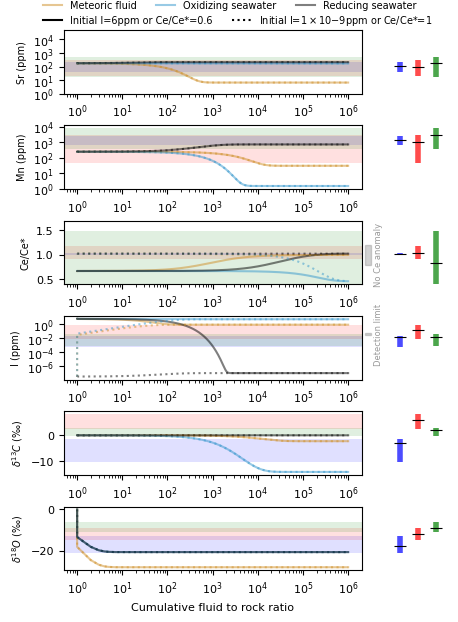

In [8]:
# plot mode results
a4_x, a4_y = (8.27, 11.69)

import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from matplotlib.ticker import LogLocator, NullFormatter
from matplotlib.lines import Line2D


matplotlib.rc('xtick', labelsize=8)
matplotlib.rc('ytick', labelsize=8)

# ==========================================================
# Shared extent definitions (USED EVERYWHERE)
# ==========================================================
extent_ranges = [(90, 0.5e5), (60, 1e6), (100, 1e6)]
extent_colors = ['green', 'red', 'blue']

# ==========================================================
# Helper functions
# ==========================================================
def formation_extent_bars_with_mean(
    ax, data, ycol, groupcol='formation',
    colors=('b','r','g'), width_frac=0.2,
    factor=1e3
):
    groups = sorted(data[groupcol].unique())
    x_positions = np.linspace(0.2, 0.8, len(groups))
    
    for formation, color, xpos in zip(groups, colors, x_positions):
        vals = data[data[groupcol] == formation][ycol].dropna()
        if ax.get_yscale() == 'log':
            vals = vals[vals > 0]
        if len(vals) == 0:
            continue
        
        y_min, y_max = vals.min()/factor, vals.max()/factor
        y_mean = vals.mean()/factor
        
        ax.vlines(x=xpos, ymin=y_min, ymax=y_max, color=color, lw=4, alpha=0.7)
        ax.hlines(y=y_mean, xmin=xpos-width_frac/2, xmax=xpos+width_frac/2,
                  color='k', lw=0.8)
    
    ax.set_xlim(0, 1)
    ax.axis('off')

def formation_horizontal_extent_shading(
    ax, data, ycol, groupcol='formation',
    colors=('b','r','g'), alpha=0.12, zorder=0, factor=1e3
):
    groups = sorted(data[groupcol].unique())
    for formation, color in zip(groups, colors):
        vals = data[data[groupcol] == formation][ycol].dropna()
        if ax.get_yscale() == 'log':
            vals = vals[vals > 0]
        if len(vals) == 0:
            continue
        ax.axhspan(vals.min()/factor, vals.max()/factor,
                   facecolor=color, alpha=alpha, zorder=zorder)

def extent_bars_above_axis(
    ax, x_ranges, y_top=1.5, height=0.02, dy=0.06,
    colors=None, alpha=0.4
):
    if colors is None:
        colors = ['k'] * len(x_ranges)

    xlim = ax.get_xlim()

    for i, ((x1, x2), color) in enumerate(zip(x_ranges, colors)):
        y = y_top - i * dy

        xa = (np.log10(x1) - np.log10(xlim[0])) / (np.log10(xlim[1]) - np.log10(xlim[0]))
        xb = (np.log10(x2) - np.log10(xlim[0])) / (np.log10(xlim[1]) - np.log10(xlim[0]))

        ax.add_patch(
            plt.Rectangle(
                (xa, y), xb - xa, height,
                transform=ax.transAxes,
                facecolor=color,
                edgecolor=color,
                alpha=alpha,
                clip_on=False
            )
        )

def vertical_y_range_bar_outside(
    ax, y1, y2,
    label=None,
    x_left=1.01, width=0.02,
    color='gray', alpha=0.35,
    label_offset=0.01, label_size=6
):
    """
    Vertical bar outside axis spanning y1–y2 (data coords),
    with optional vertical label.
    """
    ylim = ax.get_ylim()

    if ax.get_yscale() == 'log':
        ya = (np.log10(y1) - np.log10(ylim[0])) / (np.log10(ylim[1]) - np.log10(ylim[0]))
        yb = (np.log10(y2) - np.log10(ylim[0])) / (np.log10(ylim[1]) - np.log10(ylim[0]))
    else:
        ya = (y1 - ylim[0]) / (ylim[1] - ylim[0])
        yb = (y2 - ylim[0]) / (ylim[1] - ylim[0])

    # bar
    ax.add_patch(
        plt.Rectangle(
            (x_left, ya),
            width,
            yb - ya,
            transform=ax.transAxes,
            facecolor=color,
            edgecolor=color,
            alpha=alpha,
            clip_on=False
        )
    )

    # label
    if label is not None:
        ax.text(
            x_left + width + label_offset,
            0.5 * (ya + yb),
            label,
            transform=ax.transAxes,
            rotation=90,
            va='center',
            ha='left',
            fontsize=label_size,
            color=color,
            alpha=0.8,
            clip_on=False
        )

# ==========================================================
# Figure
# ==========================================================
fig, axs = plt.subplots(
    6, 2,
    figsize=[a4_x * 0.6, a4_y * 0.6],
    gridspec_kw={'width_ratios': [5, 1]},
    sharey='row'
)

# -------------------------
# Sr
# -------------------------
ax = axs[0][0]
ax.plot(re_dol_mtfl_ox.N, re_dol_mtfl_ax.Sr, color='#CF8F27', alpha=0.5, label='Meteoric fluid')
ax.plot(re_dol_oxsw_ox.N, re_dol_oxsw_ax.Sr, color='#3396CC', alpha=0.5, label='Oxidizing seawater')
ax.plot(re_dol_rdsw_ox.N, re_dol_rdsw_ax.Sr, color='k', alpha=0.5, label='Reducing seawater')
ax.plot(re_dol_mtfl_ax.N, re_dol_mtfl_ax.Sr, ls=':', color='#CF8F27', alpha=0.5)
ax.plot(re_dol_oxsw_ax.N, re_dol_oxsw_ax.Sr, ls=':', color='#3396CC', alpha=0.5)
ax.plot(re_dol_rdsw_ax.N, re_dol_rdsw_ax.Sr, ls=':', color='k', alpha=0.5)

ax.set_ylabel('Sr (ppm)', fontsize=7)
ax.set_xscale('log')
ax.set_yscale('log')
ax.set_ylim(1, 5e4)
ax.yaxis.set_major_locator(LogLocator(base=10, numticks=8))


# ax.legend(fontsize=7, frameon=False, ncol=3,
#           loc='upper left', bbox_to_anchor=(-0.1, 1.4))

# ----------------------------------------------------------
# Legend 1: fluid types
# ----------------------------------------------------------
fluid_handles, fluid_labels = ax.get_legend_handles_labels()

legend1 = ax.legend(
    handles=fluid_handles,
    labels=fluid_labels,
    fontsize=7,
    frameon=False,
    ncol=3,
    loc='upper left',
    bbox_to_anchor=(-0.1, 1.6)
)

# Keep the first legend
ax.add_artist(legend1)


# ----------------------------------------------------------
# Legend 2: sample line styles
# ----------------------------------------------------------
sample_handles = [
    Line2D(
        [0], [0],
        color='k',
        lw=1.5,
        ls='-',
        label='Initial I=6ppm or Ce/Ce*=0.6'
    ),
    Line2D(
        [0], [0],
        color='k',
        lw=1.5,
        ls=':',
        label=r'Initial I=$1\times10{-9}$ppm or Ce/Ce*=1'
    )
]

ax.legend(
    handles=sample_handles,
    fontsize=7,
    frameon=False,
    ncol=2,
    loc='upper left',
    bbox_to_anchor=(-0.1, 1.4)
)



formation_horizontal_extent_shading(
    ax, nitric_runs_ppb, '88  Sr  [ No Gas ]'
)

formation_extent_bars_with_mean(
    axs[0][1], nitric_runs_ppb, '88  Sr  [ No Gas ]'
)

# -------------------------
# Mn
# -------------------------
ax = axs[1][0]
ax.plot(re_dol_mtfl_ox.N, re_dol_mtfl_ox.Mn, color='#CF8F27', alpha=0.5)
ax.plot(re_dol_oxsw_ox.N, re_dol_oxsw_ox.Mn, color='#3396CC', alpha=0.5)
ax.plot(re_dol_rdsw_ox.N, re_dol_rdsw_ox.Mn, color='k', alpha=0.5)
ax.plot(re_dol_mtfl_ax.N, re_dol_mtfl_ax.Mn, ls=':', color='#CF8F27', alpha=0.5)
ax.plot(re_dol_oxsw_ax.N, re_dol_oxsw_ax.Mn, ls=':', color='#3396CC', alpha=0.5)
ax.plot(re_dol_rdsw_ax.N, re_dol_rdsw_ax.Mn, ls=':', color='k', alpha=0.5)

ax.set_ylabel('Mn (ppm)', fontsize=7)
ax.set_xscale('log')
ax.set_yscale('log')
ax.yaxis.set_major_locator(LogLocator(base=10, numticks=5))



formation_horizontal_extent_shading(
    ax, nitric_runs_ppb, '55 -> 55  Mn  [ H2 ]'
)

formation_extent_bars_with_mean(
    axs[1][1], nitric_runs_ppb, '55 -> 55  Mn  [ H2 ]'
)

# -------------------------
# Ce anomaly
# -------------------------
ax = axs[2][0]
ax.plot(re_dol_mtfl_ox.N, re_dol_mtfl_ox.dCe, color='#CF8F27', alpha=0.5)
ax.plot(re_dol_oxsw_ox.N, re_dol_oxsw_ox.dCe, color='#3396CC', alpha=0.5)
ax.plot(re_dol_rdsw_ox.N, re_dol_rdsw_ox.dCe, color='k', alpha=0.5)
ax.plot(re_dol_mtfl_ax.N, re_dol_mtfl_ax.dCe, ls=':', color='#CF8F27', alpha=0.5)
ax.plot(re_dol_oxsw_ax.N, re_dol_oxsw_ax.dCe, ls=':', color='#3396CC', alpha=0.5)
ax.plot(re_dol_rdsw_ax.N, re_dol_rdsw_ax.dCe, ls=':', color='k', alpha=0.5)

ax.set_ylabel(r'Ce/Ce*', fontsize=7)
ax.set_xscale('log')
ax.set_ylim(0.4, 1.7)

# legend retained (semantic)
ax.legend(fontsize=7, frameon=False)

vertical_y_range_bar_outside(ax, 0.8, 1.2, label='No Ce anomaly')

formation_horizontal_extent_shading(
    ax, all_data, 'Ce_anomaly_geom', factor=1
)

formation_extent_bars_with_mean(
    axs[2][1], all_data, 'Ce_anomaly_geom', factor=1
)

# -------------------------
# I
# -------------------------
ax = axs[3][0]
ax.plot(re_dol_mtfl_ox.N, re_dol_mtfl_ox.I, color='#CF8F27', alpha=0.5)
ax.plot(re_dol_oxsw_ox.N, re_dol_oxsw_ox.I, color='#3396CC', alpha=0.5)
ax.plot(re_dol_rdsw_ox.N, re_dol_rdsw_ox.I, color='k', alpha=0.5)
ax.plot(re_dol_mtfl_ax.N, re_dol_mtfl_ax.I, ls=':', color='#CF8F27', alpha=0.5)
ax.plot(re_dol_oxsw_ax.N, re_dol_oxsw_ax.I, ls=':', color='#3396CC', alpha=0.5)
ax.plot(re_dol_rdsw_ax.N, re_dol_rdsw_ax.I, ls=':', color='k', alpha=0.5)

ax.set_ylabel('I (ppm)', fontsize=7)
ax.set_xscale('log')
ax.set_yscale('log')
ax.yaxis.set_major_locator(LogLocator(base=10, numticks=7))

I_detection_min = 30 /1e3
I_detection_max = 50 /1e3

vertical_y_range_bar_outside(
    ax, I_detection_min, I_detection_max, label='Detection limit'
)

formation_horizontal_extent_shading(
    ax, nitric_runs_ppb, '127  I  [ No Gas ]'
)

# axs[3][1].set_yscale('log')
formation_extent_bars_with_mean(
    axs[3][1], nitric_runs_ppb, '127  I  [ No Gas ]'
)
ax.set_xlabel('Fluid to rock ratio (N)', fontsize=8)

# -------------------------
# d13C
# -------------------------
ax = axs[4][0]
ax.plot(re_dol_mtfl_ox.N, re_dol_mtfl_ox.d13C, color='#CF8F27', alpha=0.5)
ax.plot(re_dol_oxsw_ox.N, re_dol_oxsw_ox.d13C, color='#3396CC', alpha=0.5)
ax.plot(re_dol_rdsw_ox.N, re_dol_rdsw_ox.d13C, color='k', alpha=0.5)
ax.plot(re_dol_mtfl_ax.N, re_dol_mtfl_ax.d13C, ls=':', color='#CF8F27', alpha=0.5)
ax.plot(re_dol_oxsw_ax.N, re_dol_oxsw_ax.d13C, ls=':', color='#3396CC', alpha=0.5)
ax.plot(re_dol_rdsw_ax.N, re_dol_rdsw_ax.d13C, ls=':', color='k', alpha=0.5)

ax.set_ylabel(r'$\delta^{13}C$ (‰)', fontsize=7)
ax.set_xscale('log')

formation_horizontal_extent_shading(
    ax, all_data, 'd13c_sp', factor=1
)

formation_extent_bars_with_mean(
    axs[4][1], all_data, 'd13c_sp', factor=1
)

# -------------------------
# d18O
# -------------------------
ax = axs[5][0]
ax.plot(re_dol_mtfl_ox.N, re_dol_mtfl_ox.d18O, color='#CF8F27', alpha=0.5)
ax.plot(re_dol_oxsw_ox.N, re_dol_oxsw_ox.d18O, color='#3396CC', alpha=0.5)
ax.plot(re_dol_rdsw_ox.N, re_dol_rdsw_ox.d18O, color='k', alpha=0.5)
ax.plot(re_dol_mtfl_ax.N, re_dol_mtfl_ax.d18O, ls=':', color='#CF8F27', alpha=0.5)
ax.plot(re_dol_oxsw_ax.N, re_dol_oxsw_ax.d18O, ls=':', color='#3396CC', alpha=0.5)
ax.plot(re_dol_rdsw_ax.N, re_dol_rdsw_ax.d18O, ls=':', color='k', alpha=0.5)

ax.set_ylabel(r'$\delta^{18}O$ (‰)', fontsize=7)
ax.set_xlabel('Cumulative fluid to rock ratio', fontsize=8)
ax.set_xscale('log')

formation_horizontal_extent_shading(
    ax, all_data, 'd18o_sp', factor=1
)

formation_extent_bars_with_mean(
    axs[5][1], all_data, 'd18o_sp', factor=1
)
axs[5][1].set_xlabel('Extent', fontsize=8)

# ==========================================================
# Sync y-axis for both columns
# ==========================================================
fig.canvas.draw()
for i in range(4):
    ymin, ymax = axs[i][0].get_ylim()
    axs[i][1].set_ylim(ymin, ymax)

plt.subplots_adjust(wspace=0.15, hspace=0.5)
plt.savefig('plots/BannerHanson_model_dolomite.pdf', bbox_inches='tight')
# plt.close()

In [9]:
oxic_dolomite = dotdict(dict(
    # concentrations, ppm
    C = 130000,
    Ca = 217000,
    Mn = 245,
    Sr = 174,
    O = 480000,
    Mg = 130000,
    Ce = np.mean([0.011, 0.896]),
    I = 6,
    # isotopes
    d13C = 0,
    d18O = 0,
    dCe = 0.67,
))

anoxic_dolomite = dotdict(dict(
    # concentrations, ppm
    C = 130000,
    Ca = 349000,
    Mn = 245,
    Sr = 174,
    O = 480000,
    Mg = 130000,
    Ce = np.mean([0.011, 0.896]),
    I = 349000 * 0.1317 * (7.8802e-15 * mm['I']) / (0.01028 * mm['I']),
    # isotopes
    d13C = 0,
    d18O = 0,
    dCe = 1.025,
))

re_dol_mtfl_ox, rs_dol_mtfl_ox = BannerHanson(rock=oxic_dolomite, fluid=meteoric_fluid)
re_dol_oxsw_ox, rs_dol_oxsw_ox = BannerHanson(rock=oxic_dolomite, fluid=oxic_seawater)
re_dol_rdsw_ox, rs_dol_rdsw_ox = BannerHanson(rock=oxic_dolomite, fluid=reducing_seawater)

re_dol_mtfl_ax, rs_dol_mtfl_ax = BannerHanson(rock=anoxic_dolomite, fluid=meteoric_fluid)
re_dol_oxsw_ax, rs_dol_oxsw_ax = BannerHanson(rock=anoxic_dolomite, fluid=oxic_seawater)
re_dol_rdsw_ax, rs_dol_rdsw_ax = BannerHanson(rock=anoxic_dolomite, fluid=reducing_seawater)

/var/folders/5v/vrzl4plx1598hr5q_5ssvl3r0000gn/T/ipykernel_91326/3573150332.py:270: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend(fontsize=7, frameon=False)
/var/folders/5v/vrzl4plx1598hr5q_5ssvl3r0000gn/T/ipykernel_91326/3573150332.py:370: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.savefig('plots/BannerHanson_model_dolomite.pdf', bbox_inches='tight')
/var/folders/5v/vrzl4plx1598hr5q_5ssvl3r0000gn/T/ipykernel_91326/3573150332.py:370: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.savefig('plots/BannerHanson_model_dolomite.pdf', bbox_inches='tight')
/opt/anaconda3/envs/chempath/lib/python3.10/site-packages/IPython/core/pylabtools.py:170: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


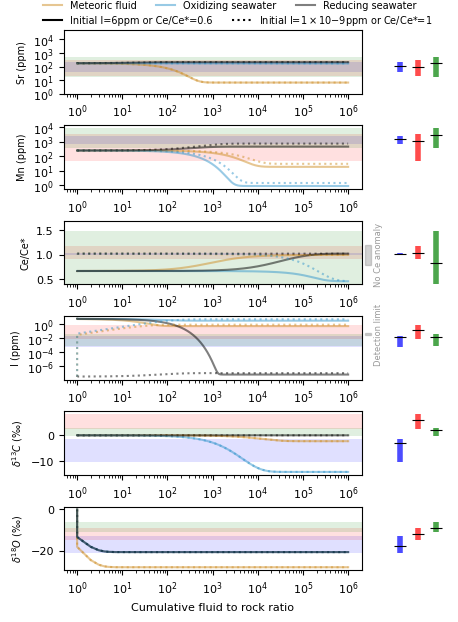

In [10]:
# plot mode results
a4_x, a4_y = (8.27, 11.69)

import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from matplotlib.ticker import LogLocator, NullFormatter
from matplotlib.lines import Line2D


matplotlib.rc('xtick', labelsize=8)
matplotlib.rc('ytick', labelsize=8)

# ==========================================================
# Shared extent definitions (USED EVERYWHERE)
# ==========================================================
extent_ranges = [(90, 0.5e5), (60, 1e6), (100, 1e6)]
extent_colors = ['green', 'red', 'blue']

# ==========================================================
# Helper functions
# ==========================================================
def formation_extent_bars_with_mean(
    ax, data, ycol, groupcol='formation',
    colors=('b','r','g'), width_frac=0.2,
    factor=1e3
):
    groups = sorted(data[groupcol].unique())
    x_positions = np.linspace(0.2, 0.8, len(groups))
    
    for formation, color, xpos in zip(groups, colors, x_positions):
        vals = data[data[groupcol] == formation][ycol].dropna()
        if ax.get_yscale() == 'log':
            vals = vals[vals > 0]
        if len(vals) == 0:
            continue
        
        y_min, y_max = vals.min()/factor, vals.max()/factor
        y_mean = vals.mean()/factor
        
        ax.vlines(x=xpos, ymin=y_min, ymax=y_max, color=color, lw=4, alpha=0.7)
        ax.hlines(y=y_mean, xmin=xpos-width_frac/2, xmax=xpos+width_frac/2,
                  color='k', lw=0.8)
    
    ax.set_xlim(0, 1)
    ax.axis('off')

def formation_horizontal_extent_shading(
    ax, data, ycol, groupcol='formation',
    colors=('b','r','g'), alpha=0.12, zorder=0, factor=1e3
):
    groups = sorted(data[groupcol].unique())
    for formation, color in zip(groups, colors):
        vals = data[data[groupcol] == formation][ycol].dropna()
        if ax.get_yscale() == 'log':
            vals = vals[vals > 0]
        if len(vals) == 0:
            continue
        ax.axhspan(vals.min()/factor, vals.max()/factor,
                   facecolor=color, alpha=alpha, zorder=zorder)

def extent_bars_above_axis(
    ax, x_ranges, y_top=1.5, height=0.02, dy=0.06,
    colors=None, alpha=0.4
):
    if colors is None:
        colors = ['k'] * len(x_ranges)

    xlim = ax.get_xlim()

    for i, ((x1, x2), color) in enumerate(zip(x_ranges, colors)):
        y = y_top - i * dy

        xa = (np.log10(x1) - np.log10(xlim[0])) / (np.log10(xlim[1]) - np.log10(xlim[0]))
        xb = (np.log10(x2) - np.log10(xlim[0])) / (np.log10(xlim[1]) - np.log10(xlim[0]))

        ax.add_patch(
            plt.Rectangle(
                (xa, y), xb - xa, height,
                transform=ax.transAxes,
                facecolor=color,
                edgecolor=color,
                alpha=alpha,
                clip_on=False
            )
        )

def vertical_y_range_bar_outside(
    ax, y1, y2,
    label=None,
    x_left=1.01, width=0.02,
    color='gray', alpha=0.35,
    label_offset=0.01, label_size=6
):
    """
    Vertical bar outside axis spanning y1–y2 (data coords),
    with optional vertical label.
    """
    ylim = ax.get_ylim()

    if ax.get_yscale() == 'log':
        ya = (np.log10(y1) - np.log10(ylim[0])) / (np.log10(ylim[1]) - np.log10(ylim[0]))
        yb = (np.log10(y2) - np.log10(ylim[0])) / (np.log10(ylim[1]) - np.log10(ylim[0]))
    else:
        ya = (y1 - ylim[0]) / (ylim[1] - ylim[0])
        yb = (y2 - ylim[0]) / (ylim[1] - ylim[0])

    # bar
    ax.add_patch(
        plt.Rectangle(
            (x_left, ya),
            width,
            yb - ya,
            transform=ax.transAxes,
            facecolor=color,
            edgecolor=color,
            alpha=alpha,
            clip_on=False
        )
    )

    # label
    if label is not None:
        ax.text(
            x_left + width + label_offset,
            0.5 * (ya + yb),
            label,
            transform=ax.transAxes,
            rotation=90,
            va='center',
            ha='left',
            fontsize=label_size,
            color=color,
            alpha=0.8,
            clip_on=False
        )

# ==========================================================
# Figure
# ==========================================================
fig, axs = plt.subplots(
    6, 2,
    figsize=[a4_x * 0.6, a4_y * 0.6],
    gridspec_kw={'width_ratios': [5, 1]},
    sharey='row'
)

# -------------------------
# Sr
# -------------------------
ax = axs[0][0]
ax.plot(re_dol_mtfl_ox.N, re_dol_mtfl_ax.Sr, color='#CF8F27', alpha=0.5, label='Meteoric fluid')
ax.plot(re_dol_oxsw_ox.N, re_dol_oxsw_ax.Sr, color='#3396CC', alpha=0.5, label='Oxidizing seawater')
ax.plot(re_dol_rdsw_ox.N, re_dol_rdsw_ax.Sr, color='k', alpha=0.5, label='Reducing seawater')
ax.plot(re_dol_mtfl_ax.N, re_dol_mtfl_ax.Sr, ls=':', color='#CF8F27', alpha=0.5)
ax.plot(re_dol_oxsw_ax.N, re_dol_oxsw_ax.Sr, ls=':', color='#3396CC', alpha=0.5)
ax.plot(re_dol_rdsw_ax.N, re_dol_rdsw_ax.Sr, ls=':', color='k', alpha=0.5)

ax.set_ylabel('Sr (ppm)', fontsize=7)
ax.set_xscale('log')
ax.set_yscale('log')
ax.set_ylim(1, 5e4)
ax.yaxis.set_major_locator(LogLocator(base=10, numticks=8))


# ax.legend(fontsize=7, frameon=False, ncol=3,
#           loc='upper left', bbox_to_anchor=(-0.1, 1.4))

# ----------------------------------------------------------
# Legend 1: fluid types
# ----------------------------------------------------------
fluid_handles, fluid_labels = ax.get_legend_handles_labels()

legend1 = ax.legend(
    handles=fluid_handles,
    labels=fluid_labels,
    fontsize=7,
    frameon=False,
    ncol=3,
    loc='upper left',
    bbox_to_anchor=(-0.1, 1.6)
)

# Keep the first legend
ax.add_artist(legend1)


# ----------------------------------------------------------
# Legend 2: sample line styles
# ----------------------------------------------------------
sample_handles = [
    Line2D(
        [0], [0],
        color='k',
        lw=1.5,
        ls='-',
        label='Initial I=6ppm or Ce/Ce*=0.6'
    ),
    Line2D(
        [0], [0],
        color='k',
        lw=1.5,
        ls=':',
        label=r'Initial I=$1\times10{-9}$ppm or Ce/Ce*=1'
    )
]

ax.legend(
    handles=sample_handles,
    fontsize=7,
    frameon=False,
    ncol=2,
    loc='upper left',
    bbox_to_anchor=(-0.1, 1.4)
)



formation_horizontal_extent_shading(
    ax, nitric_runs_ppb, '88  Sr  [ No Gas ]'
)

formation_extent_bars_with_mean(
    axs[0][1], nitric_runs_ppb, '88  Sr  [ No Gas ]'
)

# -------------------------
# Mn
# -------------------------
ax = axs[1][0]
ax.plot(re_dol_mtfl_ox.N, re_dol_mtfl_ox.Mn, color='#CF8F27', alpha=0.5)
ax.plot(re_dol_oxsw_ox.N, re_dol_oxsw_ox.Mn, color='#3396CC', alpha=0.5)
ax.plot(re_dol_rdsw_ox.N, re_dol_rdsw_ox.Mn, color='k', alpha=0.5)
ax.plot(re_dol_mtfl_ax.N, re_dol_mtfl_ax.Mn, ls=':', color='#CF8F27', alpha=0.5)
ax.plot(re_dol_oxsw_ax.N, re_dol_oxsw_ax.Mn, ls=':', color='#3396CC', alpha=0.5)
ax.plot(re_dol_rdsw_ax.N, re_dol_rdsw_ax.Mn, ls=':', color='k', alpha=0.5)

ax.set_ylabel('Mn (ppm)', fontsize=7)
ax.set_xscale('log')
ax.set_yscale('log')
ax.yaxis.set_major_locator(LogLocator(base=10, numticks=5))



formation_horizontal_extent_shading(
    ax, nitric_runs_ppb, '55 -> 55  Mn  [ H2 ]'
)

formation_extent_bars_with_mean(
    axs[1][1], nitric_runs_ppb, '55 -> 55  Mn  [ H2 ]'
)

# -------------------------
# Ce anomaly
# -------------------------
ax = axs[2][0]
ax.plot(re_dol_mtfl_ox.N, re_dol_mtfl_ox.dCe, color='#CF8F27', alpha=0.5)
ax.plot(re_dol_oxsw_ox.N, re_dol_oxsw_ox.dCe, color='#3396CC', alpha=0.5)
ax.plot(re_dol_rdsw_ox.N, re_dol_rdsw_ox.dCe, color='k', alpha=0.5)
ax.plot(re_dol_mtfl_ax.N, re_dol_mtfl_ax.dCe, ls=':', color='#CF8F27', alpha=0.5)
ax.plot(re_dol_oxsw_ax.N, re_dol_oxsw_ax.dCe, ls=':', color='#3396CC', alpha=0.5)
ax.plot(re_dol_rdsw_ax.N, re_dol_rdsw_ax.dCe, ls=':', color='k', alpha=0.5)

ax.set_ylabel(r'Ce/Ce*', fontsize=7)
ax.set_xscale('log')
ax.set_ylim(0.4, 1.7)

# legend retained (semantic)
ax.legend(fontsize=7, frameon=False)

vertical_y_range_bar_outside(ax, 0.8, 1.2, label='No Ce anomaly')

formation_horizontal_extent_shading(
    ax, all_data, 'Ce_anomaly_geom', factor=1
)

formation_extent_bars_with_mean(
    axs[2][1], all_data, 'Ce_anomaly_geom', factor=1
)

# -------------------------
# I
# -------------------------
ax = axs[3][0]
ax.plot(re_dol_mtfl_ox.N, re_dol_mtfl_ox.I, color='#CF8F27', alpha=0.5)
ax.plot(re_dol_oxsw_ox.N, re_dol_oxsw_ox.I, color='#3396CC', alpha=0.5)
ax.plot(re_dol_rdsw_ox.N, re_dol_rdsw_ox.I, color='k', alpha=0.5)
ax.plot(re_dol_mtfl_ax.N, re_dol_mtfl_ax.I, ls=':', color='#CF8F27', alpha=0.5)
ax.plot(re_dol_oxsw_ax.N, re_dol_oxsw_ax.I, ls=':', color='#3396CC', alpha=0.5)
ax.plot(re_dol_rdsw_ax.N, re_dol_rdsw_ax.I, ls=':', color='k', alpha=0.5)

ax.set_ylabel('I (ppm)', fontsize=7)
ax.set_xscale('log')
ax.set_yscale('log')
ax.yaxis.set_major_locator(LogLocator(base=10, numticks=7))

I_detection_min = 30 /1e3
I_detection_max = 50 /1e3

vertical_y_range_bar_outside(
    ax, I_detection_min, I_detection_max, label='Detection limit'
)

formation_horizontal_extent_shading(
    ax, nitric_runs_ppb, '127  I  [ No Gas ]'
)

# axs[3][1].set_yscale('log')
formation_extent_bars_with_mean(
    axs[3][1], nitric_runs_ppb, '127  I  [ No Gas ]'
)
ax.set_xlabel('Fluid to rock ratio (N)', fontsize=8)

# -------------------------
# d13C
# -------------------------
ax = axs[4][0]
ax.plot(re_dol_mtfl_ox.N, re_dol_mtfl_ox.d13C, color='#CF8F27', alpha=0.5)
ax.plot(re_dol_oxsw_ox.N, re_dol_oxsw_ox.d13C, color='#3396CC', alpha=0.5)
ax.plot(re_dol_rdsw_ox.N, re_dol_rdsw_ox.d13C, color='k', alpha=0.5)
ax.plot(re_dol_mtfl_ax.N, re_dol_mtfl_ax.d13C, ls=':', color='#CF8F27', alpha=0.5)
ax.plot(re_dol_oxsw_ax.N, re_dol_oxsw_ax.d13C, ls=':', color='#3396CC', alpha=0.5)
ax.plot(re_dol_rdsw_ax.N, re_dol_rdsw_ax.d13C, ls=':', color='k', alpha=0.5)

ax.set_ylabel(r'$\delta^{13}C$ (‰)', fontsize=7)
ax.set_xscale('log')

formation_horizontal_extent_shading(
    ax, all_data, 'd13c_sp', factor=1
)

formation_extent_bars_with_mean(
    axs[4][1], all_data, 'd13c_sp', factor=1
)

# -------------------------
# d18O
# -------------------------
ax = axs[5][0]
ax.plot(re_dol_mtfl_ox.N, re_dol_mtfl_ox.d18O, color='#CF8F27', alpha=0.5)
ax.plot(re_dol_oxsw_ox.N, re_dol_oxsw_ox.d18O, color='#3396CC', alpha=0.5)
ax.plot(re_dol_rdsw_ox.N, re_dol_rdsw_ox.d18O, color='k', alpha=0.5)
ax.plot(re_dol_mtfl_ax.N, re_dol_mtfl_ax.d18O, ls=':', color='#CF8F27', alpha=0.5)
ax.plot(re_dol_oxsw_ax.N, re_dol_oxsw_ax.d18O, ls=':', color='#3396CC', alpha=0.5)
ax.plot(re_dol_rdsw_ax.N, re_dol_rdsw_ax.d18O, ls=':', color='k', alpha=0.5)

ax.set_ylabel(r'$\delta^{18}O$ (‰)', fontsize=7)
ax.set_xlabel('Cumulative fluid to rock ratio', fontsize=8)
ax.set_xscale('log')

formation_horizontal_extent_shading(
    ax, all_data, 'd18o_sp', factor=1
)

formation_extent_bars_with_mean(
    axs[5][1], all_data, 'd18o_sp', factor=1
)
axs[5][1].set_xlabel('Extent', fontsize=8)

# ==========================================================
# Sync y-axis for both columns
# ==========================================================
fig.canvas.draw()
for i in range(4):
    ymin, ymax = axs[i][0].get_ylim()
    axs[i][1].set_ylim(ymin, ymax)

plt.subplots_adjust(wspace=0.15, hspace=0.5)
plt.savefig('plots/BannerHanson_model_dolomite.pdf', bbox_inches='tight')
# plt.close()

In [11]:
plt.figure()
ax.plot(re_dol_mtfl_ox.N, re_dol_mtfl_ox.Ca, color='#CF8F27', alpha=0.5)
ax.plot(re_dol_oxsw_ox.N, re_dol_oxsw_ox.Ca, color='#3396CC', alpha=0.5)
ax.plot(re_dol_rdsw_ox.N, re_dol_rdsw_ox.Ca, color='k', alpha=0.5)
ax.plot(re_dol_mtfl_ax.N, re_dol_mtfl_ax.Ca, ls=':', color='#CF8F27', alpha=0.5)
ax.plot(re_dol_oxsw_ax.N, re_dol_oxsw_ax.Ca, ls=':', color='#3396CC', alpha=0.5)
ax.plot(re_dol_rdsw_ax.N, re_dol_rdsw_ax.Ca, ls=':', color='k', alpha=0.5)
plt.show()

<Figure size 640x480 with 0 Axes>

In [12]:
re_dol_mtfl_ox.Ca

array([217000., 217000., 217000., ..., 217000., 217000., 217000.],
      shape=(1000000,))

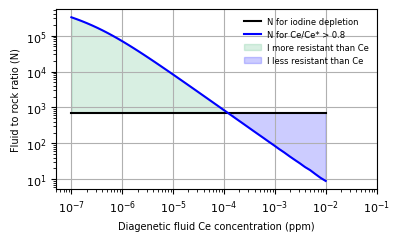

In [13]:
a4_x, a4_y = (8.27, 11.69)
data = pd.read_csv('fluid_rock_ratios_2D.csv')
data = data[data['dCe_initial'] == 1.5]
data = data.sort_values('Ce_ppm')

x = data['Ce_ppm'].values
y_I = data['N_I_depletion'].values
y_dCe = data['N_dCe_0.8'].values


plt.figure(figsize=(a4_x*0.5, a4_y*0.2))
# Plot lines instead of scatter
line_I, = plt.plot(x, y_I, color='black', lw=1.5, label='I Depletion (N)')
line_dCe, = plt.plot(x, y_dCe, color='blue', lw=1.5, label='dCe > 0.8 (N)')

# Shade areas
shade_more = plt.fill_between(x, y_I, y_dCe, where=(y_dCe > y_I), color='#3CB371', alpha=0.2)
shade_less = plt.fill_between(x, y_I, y_dCe, where=(y_dCe < y_I), color='blue', alpha=0.2)

# # Place text in middle of shaded areas
# mask_more = y_dCe > y_I
# if np.any(mask_more):
#     x_med = np.median(x[mask_more])
#     y_med = np.median((y_I[mask_more] + y_dCe[mask_more])/2)
#     plt.text(0.4e-6, y_med, 'Mosher\nsamples', 
#              fontsize=7, color='green', ha='center', va='center')

# mask_less = y_dCe < y_I
# if np.any(mask_less):
#     x_med = np.median(x[mask_less])
#     y_med = np.median((y_I[mask_less] + y_dCe[mask_less])/2)
#     plt.text(10e-3, 0.2e3, 'Gordon Lake\nKona dolomite\nEspanola samples', 
#              fontsize=7, color='blue', ha='center', va='center')

plt.xscale('log')
plt.yscale('log')
plt.xlabel('Diagenetic fluid Ce concentration (ppm)', fontsize=7)
plt.ylabel('Fluid to rock ratio (N)', fontsize=7)
# plt.title('Comparison of N for I Depletion vs dCe>0.8', fontsize=9)

# Legend for lines and shaded areas
plt.legend(handles=[line_I, line_dCe, shade_more, shade_less], 
           labels=['N for iodine depletion', 'N for Ce/Ce* > 0.8', 
                   'I more resistant than Ce', 'I less resistant than Ce'],
           fontsize=6, loc='upper right', frameon=0)
plt.xlim([5e-8, 0.1])
plt.grid()
plt.savefig('plots/IvsCe.pdf', bbox_inches='tight')

In [14]:
anoxic_aragonite


{'C': 120000,
 'Ca': 387500,
 'Mn': 1,
 'Sr': 10000,
 'O': 480000,
 'Mg': 2500,
 'Ce': np.float64(0.4535),
 'I': 3.982693707490273e-08,
 'd13C': 5,
 'd18O': 0,
 'dCe': 1.025}

In [15]:
# ==========================================================
# Rock compositions: low / high endmembers
# ==========================================================
# Mn, Sr, I, Ce = 100x lower / 100x higher than original
# Ca, C, O unchanged
# d13C = 0.5x / 2x original
# d18O = +/- 2 per mil when original = 0

# ----------------------------------------------------------
# Primary aragonite deposited in oxic column
# ----------------------------------------------------------

oxic_aragonite_low = dotdict(dict(
    # concentrations, ppm
    C = 120000,
    Ca = 387500,
    Mn = 1e-2,
    Sr = 10,
    O = 480000,
    Mg = 2500,
    Ce = np.mean([0.011, 0.896]) / 100,
    I = 6 / 100,
    # isotopes
    d13C = 2.5,
    d18O = -5,
    dCe = 0.67,
))

oxic_aragonite_high = dotdict(dict(
    # concentrations, ppm
    C = 120000,
    Ca = 387500,
    Mn = 10,
    Sr = 1e4,
    O = 480000,
    Mg = 2500,
    Ce = np.mean([0.011, 0.896]) * 100,
    I = 6 * 100,
    # isotopes
    d13C = 10,
    d18O = 5,
    dCe = 0.67,
))



# ----------------------------------------------------------
# Primary aragonite deposited in anoxic column
# ----------------------------------------------------------

anoxic_aragonite_low = dotdict(dict(
    # concentrations, ppm
    C = 120000,
    Ca = 387500,
    Mn = 1e-2,
    Sr = 10,
    O = 480000,
    Mg = 2500,
    Ce = np.mean([0.011, 0.896]) / 100,
    I = 1e-11,
    # isotopes
    d13C = 2.5,
    d18O = -5,
    dCe = 1.025,
))

anoxic_aragonite_high = dotdict(dict(
    # concentrations, ppm
    C = 120000,
    Ca = 387500,
    Mn = 10,
    Sr = 1e4,
    O = 480000,
    Mg = 2500,
    Ce = np.mean([0.011, 0.896]) * 100,
    I = 1e-7,
    # isotopes
    d13C = 10,
    d18O = 5,
    dCe = 1.025,
))




# ==========================================================
# Model runs
# ==========================================================

# ----------------------------------------------------------
# Reducing seawater
# ----------------------------------------------------------
# oxh = low initial rock composition
# oxl = high initial rock composition
re_rdsw_low, rs_rdsw_low = BannerHanson(
    rock=oxic_aragonite_low,
    fluid=reducing_seawater
)

re_rdsw_high, rs_rdsw_high = BannerHanson(
    rock=oxic_aragonite_high,
    fluid=reducing_seawater
)


# ----------------------------------------------------------
# Oxidizing seawater
# ----------------------------------------------------------
re_oxsw_low, rs_oxsw_low = BannerHanson(
    rock=oxic_aragonite_low,
    fluid=oxic_seawater
)

re_oxsw_high, rs_oxsw_high = BannerHanson(
    rock=oxic_aragonite_high,
    fluid=oxic_seawater
)


# ----------------------------------------------------------
# Meteoric fluid
# ----------------------------------------------------------
re_met_low, rs_met_low = BannerHanson(
    rock=oxic_aragonite_low,
    fluid=meteoric_fluid
)

re_met_high, rs_met_high = BannerHanson(
    rock=oxic_aragonite_high,
    fluid=meteoric_fluid
  )

# ----------------------------------------------------------
# Reducing seawater — anoxic aragonite
# ----------------------------------------------------------
re_rdsw_ana_low, rs_rdsw_ana_low = BannerHanson(
    rock=anoxic_aragonite_low,
    fluid=reducing_seawater
)

re_rdsw_ana_high, rs_rdsw_ana_high = BannerHanson(
    rock=anoxic_aragonite_high,
    fluid=reducing_seawater
)


# ----------------------------------------------------------
# Oxidizing seawater — anoxic aragonite
# ----------------------------------------------------------
re_oxsw_ana_low, rs_oxsw_ana_low = BannerHanson(
    rock=anoxic_aragonite_low,
    fluid=oxic_seawater
)

re_oxsw_ana_high, rs_oxsw_ana_high = BannerHanson(
    rock=anoxic_aragonite_high,
    fluid=oxic_seawater
)


# ----------------------------------------------------------
# Meteoric fluid — anoxic aragonite
# ----------------------------------------------------------
re_met_ana_low, rs_met_ana_low = BannerHanson(
    rock=anoxic_aragonite_low,
    fluid=meteoric_fluid
)

re_met_ana_high, rs_met_ana_high = BannerHanson(
    rock=anoxic_aragonite_high,
    fluid=meteoric_fluid
)

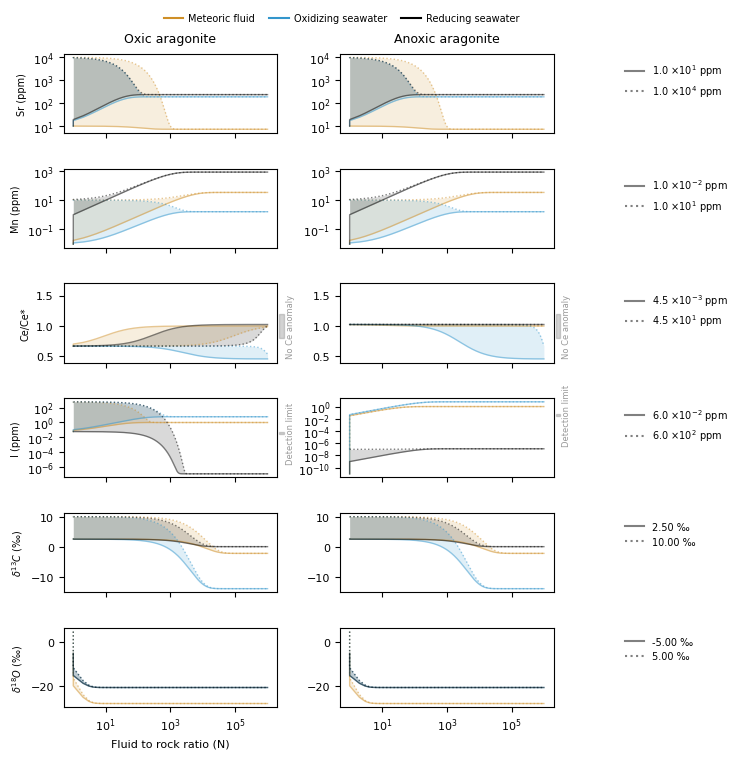

In [16]:
# ==========================================================
# Run Banner-Hanson model
# ==========================================================

a4_x, a4_y = (8.27, 11.69)

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.ticker import LogLocator
from matplotlib.lines import Line2D


# ==========================================================
# Plot settings
# ==========================================================

matplotlib.rc('xtick', labelsize=8)
matplotlib.rc('ytick', labelsize=8)


# ==========================================================
# Colors for the three fluids
# ==========================================================

COLOR_MET = '#CF8F27'       # Meteoric
COLOR_OXSW = '#3396CC'      # Oxidizing seawater
COLOR_RDSW = 'k'            # Reducing seawater


# ==========================================================
# Helper: scientific notation
# ==========================================================

def sci_label(value, decimals=1):

    value = float(value)

    if value == 0:
        return '0.00'

    exponent = int(np.floor(np.log10(abs(value))))
    coefficient = value / 10**exponent

    return (
        rf'{coefficient:.{decimals}f}'
        rf' $\times$10$^{{{exponent}}}$'
    )


# ==========================================================
# Helper function for scenario envelopes
# ==========================================================

def fill_scenario_range(
    ax,
    low,
    high,
    x='N',
    y='Sr',
    color='gray',
    alpha=0.15
):

    ax.fill_between(
        low[x],
        low[y],
        high[y],
        color=color,
        alpha=alpha,
        linewidth=0
    )


# ==========================================================
# Helper function for plotting two scenarios
# ==========================================================

def plot_scenarios(
    ax,
    low,
    high,
    y,
    color,
    alpha=0.5
):

    # ------------------------------------------------------
    # Scenario envelope
    # ------------------------------------------------------

    fill_scenario_range(
        ax,
        low,
        high,
        y=y,
        color=color,
        alpha=0.15
    )

    # ------------------------------------------------------
    # Low scenario = solid
    # ------------------------------------------------------

    ax.plot(
        low.N,
        low[y],
        color=color,
        alpha=alpha,
        lw=1.0
    )

    # ------------------------------------------------------
    # High scenario = dotted
    # ------------------------------------------------------

    ax.plot(
        high.N,
        high[y],
        color=color,
        alpha=alpha,
        ls=':',
        lw=1.0
    )


# ==========================================================
# Helper: create rock-value legend handles
# ==========================================================

def concentration_handles(
    low_rock,
    high_rock,
    property_name,
    units='ppm'
):

    low_value = getattr(
        low_rock,
        property_name
    )

    high_value = getattr(
        high_rock,
        property_name
    )

    return [

        Line2D(
            [0], [0],
            color='gray',
            lw=1.5,
            ls='-',
            label=f'{sci_label(low_value)} {units}'
        ),

        Line2D(
            [0], [0],
            color='gray',
            lw=1.5,
            ls=':',
            label=f'{sci_label(high_value)} {units}'
        )

    ]


# ==========================================================
# Helper: create isotope legend handles
# ==========================================================

def isotope_handles(
    low_rock,
    high_rock,
    property_name,
    units='‰'
):

    low_value = getattr(
        low_rock,
        property_name
    )

    high_value = getattr(
        high_rock,
        property_name
    )

    return [

        Line2D(
            [0], [0],
            color='gray',
            lw=1.5,
            ls='-',
            label=f'{low_value:.2f} {units}'
        ),

        Line2D(
            [0], [0],
            color='gray',
            lw=1.5,
            ls=':',
            label=f'{high_value:.2f} {units}'
        )

    ]


# ==========================================================
# Helper: add legend to dedicated legend axis
# ==========================================================

def add_legend_to_axis(
    ax,
    handles,
    title=None,
    fontsize=7,
    title_fontsize=7
):

    ax.legend(
        handles=handles,
        fontsize=fontsize,
        frameon=False,
        loc='upper left',
        title=title,
        title_fontsize=title_fontsize,
    )



# ==========================================================
# Vertical range bar outside axis
# ==========================================================

def vertical_y_range_bar_outside(
    ax,
    y1,
    y2,
    label=None,
    x_left=1.01,
    width=0.02,
    color='gray',
    alpha=0.35,
    label_offset=0.01,
    label_size=6
):

    ylim = ax.get_ylim()

    if ax.get_yscale() == 'log':

        ya = (
            np.log10(y1) - np.log10(ylim[0])
        ) / (
            np.log10(ylim[1]) - np.log10(ylim[0])
        )

        yb = (
            np.log10(y2) - np.log10(ylim[0])
        ) / (
            np.log10(ylim[1]) - np.log10(ylim[0])
        )

    else:

        ya = (
            y1 - ylim[0]
        ) / (
            ylim[1] - ylim[0]
        )

        yb = (
            y2 - ylim[0]
        ) / (
            ylim[1] - ylim[0]
        )

    # ------------------------------------------------------
    # Bar
    # ------------------------------------------------------

    ax.add_patch(
        plt.Rectangle(
            (x_left, ya),
            width,
            yb - ya,
            transform=ax.transAxes,
            facecolor=color,
            edgecolor=color,
            alpha=alpha,
            clip_on=False
        )
    )

    # ------------------------------------------------------
    # Label
    # ------------------------------------------------------

    if label is not None:

        ax.text(
            x_left + width + label_offset,
            0.5 * (ya + yb),
            label,
            transform=ax.transAxes,
            rotation=90,
            va='center',
            ha='left',
            fontsize=label_size,
            color=color,
            alpha=0.8,
            clip_on=False
        )


# ==========================================================
# Figure
#
# Col 0 = Oxic plots
# Col 1 = Oxic rock legends
# Col 2 = Anoxic plots
# Col 3 = Anoxic rock legends
# ==========================================================

fig, axs = plt.subplots(
    6,
    3,
    figsize=[a4_x * 0.8, a4_y * 0.65],
    sharex='col',

    gridspec_kw={
        'width_ratios': [1.0, 1.0, 0.2]
    }
)


# ==========================================================
# Column definitions
# ==========================================================

rock_columns = [

    

    # ------------------------------------------------------
    # Oxic aragonite
    # ------------------------------------------------------

    {
        'title': 'Oxic aragonite',

        'low_rock': oxic_aragonite_low,
        'high_rock': oxic_aragonite_high,

        'met_low': re_met_low,
        'met_high': re_met_high,

        'oxsw_low': re_oxsw_low,
        'oxsw_high': re_oxsw_high,

        'rdsw_low': re_rdsw_low,
        'rdsw_high': re_rdsw_high,
    },

    # ------------------------------------------------------
    # Anoxic aragonite
    # ------------------------------------------------------

    {
        'title': 'Anoxic aragonite',

        'low_rock': anoxic_aragonite_low,
        'high_rock': anoxic_aragonite_high,

        'met_low': re_met_ana_low,
        'met_high': re_met_ana_high,

        'oxsw_low': re_oxsw_ana_low,
        'oxsw_high': re_oxsw_ana_high,

        'rdsw_low': re_rdsw_ana_low,
        'rdsw_high': re_rdsw_ana_high,
    }
]


# ==========================================================
# Variables
# ==========================================================

y_variables = [
    'Sr',
    'Mn',
    'dCe',
    'I',
    'd13C',
    'd18O'
]


y_labels = [
    'Sr (ppm)',
    'Mn (ppm)',
    r'Ce/Ce*',
    'I (ppm)',
    r'$\delta^{13}C$ (‰)',
    r'$\delta^{18}O$ (‰)'
]


# ==========================================================
# Plot model results
# ==========================================================

# Model columns:
#
# rock_columns[0] -> column 0
# rock_columns[1] -> column 1

plot_columns = [0,1]


for rock, col in zip(
    rock_columns,
    plot_columns
):

    # ------------------------------------------------------
    # Column title
    # ------------------------------------------------------

    axs[0, col].set_title(
        rock['title'],
        fontsize=9,
        pad=8
    )

    # ------------------------------------------------------
    # Loop through rows
    # ------------------------------------------------------

    for row, (y, ylabel) in enumerate(
        zip(y_variables, y_labels)
    ):

        ax = axs[row, col]

        # ==================================================
        # Meteoric fluid
        # ==================================================

        plot_scenarios(
            ax,
            rock['met_low'],
            rock['met_high'],
            y=y,
            color=COLOR_MET
        )

        # ==================================================
        # Oxidizing seawater
        # ==================================================

        plot_scenarios(
            ax,
            rock['oxsw_low'],
            rock['oxsw_high'],
            y=y,
            color=COLOR_OXSW
        )

        # ==================================================
        # Reducing seawater
        # ==================================================

        plot_scenarios(
            ax,
            rock['rdsw_low'],
            rock['rdsw_high'],
            y=y,
            color=COLOR_RDSW
        )

        # ==================================================
        # Y labels
        #
        # Only show on the left-most plot column.
        # ==================================================

        if col == 0:

            ax.set_ylabel(
                ylabel,
                fontsize=7
            )

        # ==================================================
        # X scale
        # ==================================================

        ax.set_xscale('log')

        # ==================================================
        # Sr
        # ==================================================

        if y == 'Sr':

            ax.set_yscale('log')

            ax.yaxis.set_major_locator(
                LogLocator(
                    base=10,
                    numticks=8
                )
            )

        # ==================================================
        # Mn
        # ==================================================

        elif y == 'Mn':

            ax.set_yscale('log')

            ax.yaxis.set_major_locator(
                LogLocator(
                    base=10,
                    numticks=5
                )
            )

        # ==================================================
        # Ce anomaly
        # ==================================================

        elif y == 'dCe':

            ax.set_ylim(
                0.4,
                1.7
            )

            vertical_y_range_bar_outside(
                ax,
                0.8,
                1.2,
                label='No Ce anomaly'
            )

        # ==================================================
        # I
        # ==================================================

        elif y == 'I':

            ax.set_yscale('log')

            ax.yaxis.set_major_locator(
                LogLocator(
                    base=10,
                    numticks=7
                )
            )

            I_detection_min = 30 / 1e3
            I_detection_max = 50 / 1e3

            vertical_y_range_bar_outside(
                ax,
                I_detection_min,
                I_detection_max,
                label='Detection limit'
            )


# ==========================================================
# Dedicated legend columns
# ==========================================================

legend_columns = [2]


for rock, legend_col in zip(
    rock_columns,
    legend_columns
):

    # ------------------------------------------------------
    # Remove axes appearance
    # ------------------------------------------------------

    for row in range(6):
        axs[row, legend_col].axis('off')




    # ======================================================
    # Sr legend
    # ======================================================

    add_legend_to_axis(
        axs[0, legend_col],
        concentration_handles(
            rock['low_rock'],
            rock['high_rock'],
            property_name='Sr',
            units='ppm'
        ),
        fontsize=7
    )


    # ======================================================
    # Mn legend
    # ======================================================

    add_legend_to_axis(
        axs[1, legend_col],
        concentration_handles(
            rock['low_rock'],
            rock['high_rock'],
            property_name='Mn',
            units='ppm'
        ),
        fontsize=7
    )


    # ======================================================
    # Ce legend
    # ======================================================

    add_legend_to_axis(
        axs[2, legend_col],
        concentration_handles(
            rock['low_rock'],
            rock['high_rock'],
            property_name='Ce',
            units='ppm'
        ),
        fontsize=7
    )


    # ======================================================
    # I legend
    # ======================================================

    add_legend_to_axis(
        axs[3, legend_col],
        concentration_handles(
            rock['low_rock'],
            rock['high_rock'],
            property_name='I',
            units='ppm'
        ),
        fontsize=7
    )


    # ======================================================
    # d13C legend
    # ======================================================

    add_legend_to_axis(
        axs[4, legend_col],
        isotope_handles(
            rock['low_rock'],
            rock['high_rock'],
            property_name='d13C'
        ),
        fontsize=7
    )


    # ======================================================
    # d18O legend
    # ======================================================

    add_legend_to_axis(
        axs[5, legend_col],
        isotope_handles(
            rock['low_rock'],
            rock['high_rock'],
            property_name='d18O'
        ),
        fontsize=7
    )


# ==========================================================
# Fluid legend
# ==========================================================

fluid_handles = [

    Line2D(
        [0], [0],
        color=COLOR_MET,
        lw=1.5,
        label='Meteoric fluid'
    ),

    Line2D(
        [0], [0],
        color=COLOR_OXSW,
        lw=1.5,
        label='Oxidizing seawater'
    ),

    Line2D(
        [0], [0],
        color=COLOR_RDSW,
        lw=1.5,
        label='Reducing seawater'
    )

]


fig.legend(
    handles=fluid_handles,
    fontsize=7,
    frameon=False,
    ncol=3,
    loc='upper center',
    bbox_to_anchor=(0.5, 0.995),
    handlelength=2.0,
    handletextpad=0.5,
    columnspacing=1.5
)


# ==========================================================
# X-axis labels
# ==========================================================

axs[5, 0].set_xlabel(
    'Fluid to rock ratio (N)',
    fontsize=8
)

axs[5, 2].set_xlabel(
    'Fluid to rock ratio (N)',
    fontsize=8
)


# ==========================================================
# Layout
# ==========================================================

plt.subplots_adjust(
    left=0.08,
    right=0.98,
    bottom=0.07,
    top=0.93,
    wspace=0.4,
    hspace=0.45
)


# ==========================================================
# Save / show
# ==========================================================

# plt.show()

plt.savefig(
    'plots/banner_hanson_sensitivity_initial_rock.png',
    dpi=600,
    bbox_inches='tight'
)

# plt.close()


In [17]:
# ==========================================================
# Fluid endmember sensitivity
# ==========================================================
#
# Low / high fluid compositions
#
# Mn, Sr, Ce, I:
#     sensitivity ranges defined below
#
# C, Ca, O, Mg:
#     unchanged
#
# d13C, d18O:
#     specified low/high values
#
# ==========================================================


# ----------------------------------------------------------
# Oxic seawater
# ----------------------------------------------------------

oxic_seawater_low = dotdict(dict(
    # concentrations in ppm
    C = 29,
    Ca = 0.01028 * mm['Ca'] * 1e3,
    Mn = 1e-3,
    Sr = 1e-1,
    O = 889e3,
    Mg = 1295,
    Ce = 1e-7,
    I = 1e-6,

    # isotopes
    d13C = -5,
    d18O = -35.5,
    dCe = 0.46,
))


oxic_seawater_high = dotdict(dict(
    # concentrations in ppm
    C = 29,
    Ca = 0.01028 * mm['Ca'] * 1e3,
    Mn = 1e-2,
    Sr = 10,
    O = 889e3,
    Mg = 1295,
    Ce = 1e-5,
    I = 1e-4,

    # isotopes
    d13C = -15,
    d18O = -25.5,
    dCe = 0.46,
))


# ----------------------------------------------------------
# Reducing seawater
# ----------------------------------------------------------

reducing_seawater_low = dotdict(dict(
    # concentrations in ppm
    C = 29,
    Ca = 0.01028 * mm['Ca'] * 1e3,
    Mn = 1e-1,
    Sr = 1e-1,
    O = 889e3,
    Mg = 1295,
    Ce = 1e-7,
    I = 1e-9,

    # isotopes
    d13C = -5,
    d18O = -35,
    dCe = np.mean((0.8, 1.25)),
))


reducing_seawater_high = dotdict(dict(
    # concentrations in ppm
    C = 29,
    Ca = 0.01028 * mm['Ca'] * 1e3,
    Mn = 10,
    Sr = 10,
    O = 889e3,
    Mg = 1295,
    Ce = 1e-5,
    I = 1e-7,

    # isotopes
    d13C = 1,
    d18O = -25,
    dCe = np.mean((0.8, 1.25)),
))


# ----------------------------------------------------------
# Meteoric fluid
# ----------------------------------------------------------

meteoric_fluid_low = dotdict(dict(
    # concentrations in ppm
    C = 10,
    Ca = 0.002 * mm['Ca'] * 1e3,
    Mn = 1e-2,
    Sr = 1e-1,
    O = 889e3,
    Mg = np.mean((0.8, 235)),
    Ce = 1e-5,
    I = 1e-2,

    # isotopes
    d13C = -5,
    d18O = -37,
    dCe = 1,
))


meteoric_fluid_high = dotdict(dict(
    # concentrations in ppm
    C = 10,
    Ca = 0.002 * mm['Ca'] * 1e3,
    Mn = 1,
    Sr = 10,
    O = 889e3,
    Mg = np.mean((0.8, 235)),
    Ce = 1e-3,
    I = 1e-1,

    # isotopes
    d13C = 0,
    d18O = -27,
    dCe = 1,
))


# ==========================================================
# Queue all fluid scenarios
# ==========================================================

fluid_scenarios = {

    # ------------------------------------------------------
    # Oxidizing seawater
    # ------------------------------------------------------

    "oxic_low": oxic_seawater_low,
    "oxic_high": oxic_seawater_high,

    # ------------------------------------------------------
    # Reducing seawater
    # ------------------------------------------------------

    "reducing_low": reducing_seawater_low,
    "reducing_high": reducing_seawater_high,

    # ------------------------------------------------------
    # Meteoric fluid
    # ------------------------------------------------------

    "meteoric_low": meteoric_fluid_low,
    "meteoric_high": meteoric_fluid_high,
}


# ==========================================================
# Queue rock scenarios
# ==========================================================

rock_scenarios = {

    "oxic_aragonite": oxic_aragonite,

    "anoxic_aragonite": anoxic_aragonite,
}


# ==========================================================
# Run Banner-Hanson model
# ==========================================================

model_results = {}


for rock_name, rock in rock_scenarios.items():

    for fluid_name, fluid in fluid_scenarios.items():

        scenario_name = f"{rock_name}_{fluid_name}"

        print(
            f"Running {scenario_name}..."
        )

        rock_evolution, solution_evolution = BannerHanson(
            rock=rock,
            fluid=fluid
        )

        model_results[scenario_name] = {

            "rock": rock_evolution,

            "fluid": solution_evolution,

            "rock_type": rock_name,

            "fluid_type": fluid_name,
        }


print(
    "\nAll models completed."
)

print(
    f"Total model runs: {len(model_results)}"
)

Running oxic_aragonite_oxic_low...
Running oxic_aragonite_oxic_high...
Running oxic_aragonite_reducing_low...
Running oxic_aragonite_reducing_high...
Running oxic_aragonite_meteoric_low...
Running oxic_aragonite_meteoric_high...
Running anoxic_aragonite_oxic_low...
Running anoxic_aragonite_oxic_high...
Running anoxic_aragonite_reducing_low...
Running anoxic_aragonite_reducing_high...
Running anoxic_aragonite_meteoric_low...
Running anoxic_aragonite_meteoric_high...

All models completed.
Total model runs: 12


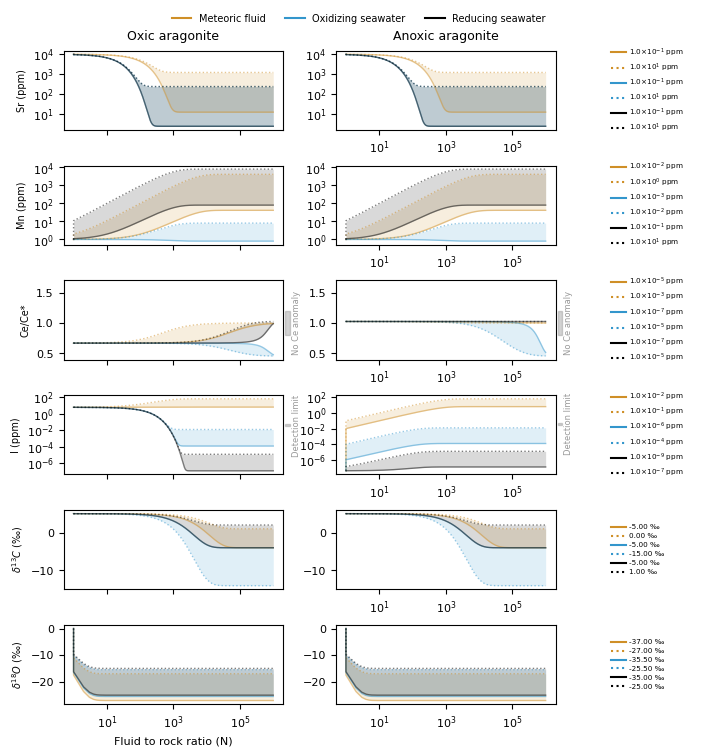

In [18]:
# ==========================================================
# Fluid sensitivity — Banner-Hanson model
# Oxic vs. anoxic aragonite
#
# COLUMN 1 = Oxic aragonite plots
# COLUMN 2 = Oxic aragonite labels
# COLUMN 3 = Anoxic aragonite plots
# COLUMN 4 = Anoxic aragonite labels
# ==========================================================

a4_x, a4_y = (8.27, 11.69)

import matplotlib
import matplotlib.pyplot as plt
import numpy as np

from matplotlib.ticker import LogLocator
from matplotlib.lines import Line2D


# ==========================================================
# Plot settings
# ==========================================================

matplotlib.rc('xtick', labelsize=8)
matplotlib.rc('ytick', labelsize=8)


# ==========================================================
# Colors for the three fluids
# ==========================================================

COLOR_MET = '#CF8F27'       # Meteoric
COLOR_OXSW = '#3396CC'      # Oxidizing seawater
COLOR_RDSW = 'k'            # Reducing seawater


# ==========================================================
# Helper: scientific notation
# ==========================================================

def sci_label(value, decimals=1):
    """
    Format a number as scientific notation.

    Examples:
        0.06    -> 6.0 × 10^-2
        600     -> 6.0 × 10^2
        10000   -> 1.0 × 10^4
    """

    value = float(value)

    if value == 0:
        return '0.0'

    exponent = int(np.floor(np.log10(abs(value))))
    coefficient = value / 10**exponent

    return (
        rf'{coefficient:.{decimals}f}'
        rf'$\times$10$^{{{exponent}}}$'
    )


# ==========================================================
# Helper: isotope label
# ==========================================================

def isotope_label(value, decimals=2):
    """
    Format isotope values with two decimal places.
    """

    return f'{float(value):.{decimals}f}'


# ==========================================================
# Helper: fill low-high scenario range
# ==========================================================

def fill_scenario_range(
    ax,
    low,
    high,
    x='N',
    y='Sr',
    color='gray',
    alpha=0.15
):

    ax.fill_between(
        low[x],
        low[y],
        high[y],
        color=color,
        alpha=alpha,
        linewidth=0
    )


# ==========================================================
# Helper: plot low/high fluid scenarios
# ==========================================================

def plot_scenarios(
    ax,
    low,
    high,
    y,
    color,
    alpha=0.5
):

    # ------------------------------------------------------
    # Low-high envelope
    # ------------------------------------------------------

    fill_scenario_range(
        ax,
        low,
        high,
        y=y,
        color=color,
        alpha=0.15
    )

    # ------------------------------------------------------
    # Low fluid composition = solid
    # ------------------------------------------------------

    ax.plot(
        low.N,
        low[y],
        color=color,
        alpha=alpha,
        lw=1.0
    )

    # ------------------------------------------------------
    # High fluid composition = dotted
    # ------------------------------------------------------

    ax.plot(
        high.N,
        high[y],
        color=color,
        alpha=alpha,
        ls=':',
        lw=1.0
    )


# ==========================================================
# Helper: fluid-property legend
# ==========================================================

def add_fluid_property_legend(
    ax,
    fluid_data,
    property_name,
    units='ppm',
    location='center left',
    fontsize=5.2
):
    """
    Add a legend showing low/high fluid-property values
    for all three fluids.

    Solid = low fluid composition
    Dotted = high fluid composition

    The legend is placed on a dedicated, blank subplot.
    """

    low_met = fluid_data['met_low']
    high_met = fluid_data['met_high']

    low_oxsw = fluid_data['oxsw_low']
    high_oxsw = fluid_data['oxsw_high']

    low_rdsw = fluid_data['rdsw_low']
    high_rdsw = fluid_data['rdsw_high']


    # ------------------------------------------------------
    # Determine formatting
    # ------------------------------------------------------

    if property_name in ['d13C', 'd18O']:

        def fmt(value):
            return isotope_label(value)

    else:

        def fmt(value):
            return sci_label(value)


    # ------------------------------------------------------
    # Create handles
    # ------------------------------------------------------

    handles = [

        # ==================================================
        # Meteoric
        # ==================================================

        Line2D(
            [0], [0],
            color=COLOR_MET,
            lw=1.5,
            ls='-',
            label=(
                f'{fmt(low_met[property_name])} {units}'
            )
        ),

        Line2D(
            [0], [0],
            color=COLOR_MET,
            lw=1.5,
            ls=':',
            label=(
                f'{fmt(high_met[property_name])} {units}'
            )
        ),


        # ==================================================
        # Oxidizing seawater
        # ==================================================

        Line2D(
            [0], [0],
            color=COLOR_OXSW,
            lw=1.5,
            ls='-',
            label=(
                f'{fmt(low_oxsw[property_name])} {units}'
            )
        ),

        Line2D(
            [0], [0],
            color=COLOR_OXSW,
            lw=1.5,
            ls=':',
            label=(
                f'{fmt(high_oxsw[property_name])} {units}'
            )
        ),


        # ==================================================
        # Reducing seawater
        # ==================================================

        Line2D(
            [0], [0],
            color=COLOR_RDSW,
            lw=1.5,
            ls='-',
            label=(
                f'{fmt(low_rdsw[property_name])} {units}'
            )
        ),

        Line2D(
            [0], [0],
            color=COLOR_RDSW,
            lw=1.5,
            ls=':',
            label=(
                f'{fmt(high_rdsw[property_name])} {units}'
            )
        )
    ]


    # ------------------------------------------------------
    # Add legend to dedicated legend axis
    # ------------------------------------------------------

    ax.legend(
        handles=handles,
        fontsize=fontsize,
        frameon=False,
        loc=location,
        handlelength=2.0,
        handletextpad=0.5,
        labelspacing=0.4,
        borderaxespad=0
    )


# ==========================================================
# Helper: add scenario-style legend
# ==========================================================

def add_scenario_legend(
    ax,
    fontsize=5.5
):
    """
    Explain solid/dotted line styles.
    """

    handles = [

        Line2D(
            [0], [0],
            color='0.25',
            lw=1.5,
            ls='-',
            label='Low fluid composition'
        ),

        Line2D(
            [0], [0],
            color='0.25',
            lw=1.5,
            ls=':',
            label='High fluid composition'
        )
    ]

    ax.legend(
        handles=handles,
        fontsize=fontsize,
        frameon=False,
        loc='center left',
        handlelength=2.0,
        handletextpad=0.5,
        labelspacing=0.5
    )


# ==========================================================
# Helper: vertical range bar outside axis
# ==========================================================

def vertical_y_range_bar_outside(
    ax,
    y1,
    y2,
    label=None,
    x_left=1.01,
    width=0.02,
    color='gray',
    alpha=0.35,
    label_offset=0.01,
    label_size=6
):

    ylim = ax.get_ylim()

    if ax.get_yscale() == 'log':

        ya = (
            np.log10(y1) - np.log10(ylim[0])
        ) / (
            np.log10(ylim[1]) - np.log10(ylim[0])
        )

        yb = (
            np.log10(y2) - np.log10(ylim[0])
        ) / (
            np.log10(ylim[1]) - np.log10(ylim[0])
        )

    else:

        ya = (
            y1 - ylim[0]
        ) / (
            ylim[1] - ylim[0]
        )

        yb = (
            y2 - ylim[0]
        ) / (
            ylim[1] - ylim[0]
        )


    # ------------------------------------------------------
    # Bar
    # ------------------------------------------------------

    ax.add_patch(
        plt.Rectangle(
            (x_left, ya),
            width,
            yb - ya,
            transform=ax.transAxes,
            facecolor=color,
            edgecolor=color,
            alpha=alpha,
            clip_on=False
        )
    )


    # ------------------------------------------------------
    # Label
    # ------------------------------------------------------

    if label is not None:

        ax.text(
            x_left + width + label_offset,
            0.5 * (ya + yb),
            label,
            transform=ax.transAxes,
            rotation=90,
            va='center',
            ha='left',
            fontsize=label_size,
            color=color,
            alpha=0.8,
            clip_on=False
        )


# ==========================================================
# Fluid legend
# ==========================================================

fluid_handles = [

    Line2D(
        [0], [0],
        color=COLOR_MET,
        lw=1.5,
        label='Meteoric fluid'
    ),

    Line2D(
        [0], [0],
        color=COLOR_OXSW,
        lw=1.5,
        label='Oxidizing seawater'
    ),

    Line2D(
        [0], [0],
        color=COLOR_RDSW,
        lw=1.5,
        label='Reducing seawater'
    )
]


# ==========================================================
# Figure
# ==========================================================

fig, axs = plt.subplots(
    6,
    3,

    figsize=[
        a4_x * 0.85,
        a4_y * 0.65
    ],

    sharex=False,

    gridspec_kw={
        'width_ratios': [
            1.0,    # Oxic plot
            1.0,    # Anoxic plot
            0.4    # Anoxic labels
        ]
    }
)


# ==========================================================
# Fluid property data
# ==========================================================

fluid_data = {

    'met_low': meteoric_fluid_low,
    'met_high': meteoric_fluid_high,

    'oxsw_low': oxic_seawater_low,
    'oxsw_high': oxic_seawater_high,

    'rdsw_low': reducing_seawater_low,
    'rdsw_high': reducing_seawater_high,
}


# ==========================================================
# Model result helper
# ==========================================================

def get_result(rock_name, fluid_name):

    return model_results[
        f'{rock_name}_{fluid_name}'
    ]['rock']


# ==========================================================
# Column definitions
# ==========================================================

rock_columns = [

    {
        'name': 'oxic_aragonite',
        'title': 'Oxic aragonite',
        'plot_col': 0,
        'legend_col': None
    },

    {
        'name': 'anoxic_aragonite',
        'title': 'Anoxic aragonite',
        'plot_col': 1,
        'legend_col': 2
    }
]


# ==========================================================
# Variables
# ==========================================================

y_variables = [
    'Sr',
    'Mn',
    'dCe',
    'I',
    'd13C',
    'd18O'
]


y_labels = [
    'Sr (ppm)',
    'Mn (ppm)',
    r'Ce/Ce*',
    'I (ppm)',
    r'$\delta^{13}C$ (‰)',
    r'$\delta^{18}O$ (‰)'
]


# ==========================================================
# Plot
# ==========================================================

for rock in rock_columns:

    # ------------------------------------------------------
    # Identify plot and label columns
    # ------------------------------------------------------

    plot_col = rock['plot_col']
    legend_col = rock['legend_col']


    # ------------------------------------------------------
    # Column title
    # ------------------------------------------------------

    axs[0, plot_col].set_title(
        rock['title'],
        fontsize=9,
        pad=8
    )


    # ------------------------------------------------------
    # Make legend column blank
    # ------------------------------------------------------

    if legend_col:
        for row in range(6):
            axs[row, legend_col].axis('off')


    # ------------------------------------------------------
    # Loop through variables
    # ------------------------------------------------------

    for row, (y, ylabel) in enumerate(
        zip(y_variables, y_labels)
    ):

        # ==================================================
        # Plot axis
        # ==================================================

        ax = axs[row, plot_col]


        # ==================================================
        # Legend axis
        # ==================================================

        if legend_col:
            legend_ax = axs[row, legend_col]


        # ==================================================
        # Retrieve model results
        # ==================================================

        met_low = get_result(
            rock['name'],
            'meteoric_low'
        )

        met_high = get_result(
            rock['name'],
            'meteoric_high'
        )

        oxsw_low = get_result(
            rock['name'],
            'oxic_low'
        )

        oxsw_high = get_result(
            rock['name'],
            'oxic_high'
        )

        rdsw_low = get_result(
            rock['name'],
            'reducing_low'
        )

        rdsw_high = get_result(
            rock['name'],
            'reducing_high'
        )


        # ==================================================
        # Meteoric fluid
        # ==================================================

        plot_scenarios(
            ax,
            met_low,
            met_high,
            y=y,
            color=COLOR_MET
        )


        # ==================================================
        # Oxidizing seawater
        # ==================================================

        plot_scenarios(
            ax,
            oxsw_low,
            oxsw_high,
            y=y,
            color=COLOR_OXSW
        )


        # ==================================================
        # Reducing seawater
        # ==================================================

        plot_scenarios(
            ax,
            rdsw_low,
            rdsw_high,
            y=y,
            color=COLOR_RDSW
        )


        # ==================================================
        # Y labels
        # ==================================================

        if plot_col==0:
            ax.set_ylabel(
                ylabel,
                fontsize=7
            )


        # ==================================================
        # X scale
        # ==================================================

        ax.set_xscale('log')


        # ==================================================
        # Sr
        # ==================================================

        if y == 'Sr':

            ax.set_yscale('log')

            ax.yaxis.set_major_locator(
                LogLocator(
                    base=10,
                    numticks=8
                )
            )

            if legend_col:
                add_fluid_property_legend(
                    legend_ax,
                    fluid_data,
                    property_name='Sr',
                    units='ppm',
                    location='center left'
                )


        # ==================================================
        # Mn
        # ==================================================

        elif y == 'Mn':

            ax.set_yscale('log')

            ax.yaxis.set_major_locator(
                LogLocator(
                    base=10,
                    numticks=6
                )
            )

            if legend_col:
                add_fluid_property_legend(
                    legend_ax,
                    fluid_data,
                    property_name='Mn',
                    units='ppm',
                    location='center left'
                )


        # ==================================================
        # Ce anomaly
        # ==================================================

        elif y == 'dCe':

            ax.set_ylim(
                0.4,
                1.7
            )

            # ------------------------------------------------
            # No Ce anomaly
            # ------------------------------------------------

            vertical_y_range_bar_outside(
                ax,
                0.8,
                1.2,
                label='No Ce anomaly'
            )

            if legend_col:
                add_fluid_property_legend(
                    legend_ax,
                    fluid_data,
                    property_name='Ce',
                    units='ppm',
                    location='center left'
                )


        # ==================================================
        # I
        # ==================================================

        elif y == 'I':

            ax.set_yscale('log')

            ax.yaxis.set_major_locator(
                LogLocator(
                    base=10,
                    numticks=7
                )
            )


            # ------------------------------------------------
            # I detection limit
            # ------------------------------------------------

            I_detection_min = 30 / 1e3
            I_detection_max = 50 / 1e3

            vertical_y_range_bar_outside(
                ax,
                I_detection_min,
                I_detection_max,
                label='Detection limit'
            )

            if legend_col:
                add_fluid_property_legend(
                    legend_ax,
                    fluid_data,
                    property_name='I',
                    units='ppm',
                    location='center left'
                )


        # ==================================================
        # d13C
        # ==================================================

        elif y == 'd13C':

            if legend_col:
                add_fluid_property_legend(
                    legend_ax,
                    fluid_data,
                    property_name='d13C',
                    units='‰',
                    location='center left'
                )


        # ==================================================
        # d18O
        # ==================================================

        elif y == 'd18O':

            if legend_col:
                add_fluid_property_legend(
                    legend_ax,
                    fluid_data,
                    property_name='d18O',
                    units='‰',
                    location='center left'
                )


# ==========================================================
# Figure-level fluid legend
# ==========================================================

fig.legend(
    handles=fluid_handles,
    fontsize=7,
    frameon=False,
    ncol=3,
    loc='upper center',
    bbox_to_anchor=(0.5, 1)
)


# ==========================================================
# X-axis labels
# ==========================================================

axs[5, 0].set_xlabel(
    'Fluid to rock ratio (N)',
    fontsize=8
)

axs[5, 2].set_xlabel(
    'Fluid to rock ratio (N)',
    fontsize=8
)


# ==========================================================
# Remove x tick labels from upper rows
# ==========================================================

for row in range(5):

    axs[row, 0].tick_params(
        labelbottom=False
    )

    axs[row, 2].tick_params(
        labelbottom=False
    )




# ==========================================================
# Layout
# ==========================================================

plt.subplots_adjust(
    top=0.94,
    bottom=0.08,
    left=0.08,
    right=0.98,

    # Space between:
    # oxic plot | oxic legend | anoxic plot | anoxic legend
    wspace=0.3,

    hspace=0.45
)


# ==========================================================
# Save / show
# ==========================================================


plt.savefig(
    'plots/banner_hanson_sensitivity_initial_fluid.png',
    dpi=600,
    bbox_inches='tight'
)

# plt.close()
